\
# Detección de anomalías mecánicas mediante análisis acústico
## Proyecto final – Motores Brushless DC (BLDC)

**Objetivo:** analizar grabaciones acústicas de motores BLDC A2212 para estudiar las condiciones `Healthy`, `Propeller` y `Bearing`, combinando exploración de señales, modelos supervisados y técnicas no supervisadas.

### Organización por entregas

| Entrega | Contenido | Productos principales |
|---|---|---|
| **01 – Exploración acústica** | Inventario, calidad, forma de onda, RMS, IQR, espectrograma, Mel y extracción de rasgos | `inventario_audio.csv`, figuras y matriz de características |
| **02 – Aprendizaje supervisado** | Partición, validación cruzada, Decision Tree, Random Forest, SVM y MLP | métricas, curvas, matrices de confusión y modelos |
| **Final – Aprendizaje no supervisado** | StandardScaler, PCA (2 componentes), K-means, búsqueda de DBSCAN y t-SNE opcional | embeddings, parámetros, etiquetas de clúster y visualizaciones |

### Alcance y precisión

El conjunto suministrado contiene 43 grabaciones de motores BLDC en condiciones controladas. Este trabajo constituye una **prueba de concepto sobre componentes rotativos**; no es una validación directa en motocicletas completas.

**Distinción clave:** las entregas 01 y 02 describen y clasifican condiciones conocidas. En la entrega final, K-means y DBSCAN agrupan por similitud sin utilizar las etiquetas durante el ajuste. Las etiquetas reales se usan únicamente después para interpretar y comparar los grupos.

### Índice

1. [Entrega 01 – Exploración y caracterización](#entrega-01--exploración-y-caracterización-acústica)
2. [Entrega 02 – Modelos supervisados](#entrega-02--aprendizaje-supervisado)
3. [Entrega final – Reducción y clustering](#entrega-final--aprendizaje-no-supervisado)
4. [Conclusiones y guía de sustentación](#conclusiones-y-puntos-para-la-sustentación)

> Ejecutar todas las celdas en orden desde el principio. Los archivos originales se conservan en `data/00_raw`; los resultados derivados se guardan por entrega para no duplicar ni alterar los audios originales.


# ENTREGA 01 – EXPLORACIÓN Y CARACTERIZACIÓN ACÚSTICA

## 1. ¿Qué se busca identificar?

Una variación en el sonido de una máquina puede estar relacionada con cambios en su funcionamiento. En este proyecto trabajamos con tres etiquetas presentes en las carpetas del dataset:

- **Healthy:** motor en condición saludable.
- **Propeller:** condición asociada a la hélice.
- **Bearing:** condición asociada al rodamiento.

La tarea de esta entrega es una **clasificación supervisada de tres clases**. Se interpreta `Healthy` como condición normal y las otras dos etiquetas como condiciones anómalas conocidas. No es todavía un detector de anomalías desconocidas (*novelty detection*), porque el modelo aprende a partir de ejemplos etiquetados de las tres condiciones.

> **Precaución de interpretación:** la etiqueta del modelo representa la carpeta/condición del dataset; no constituye por sí sola un diagnóstico industrial ni demuestra causalidad mecánica.


## 2. Dataset y observaciones iniciales

El archivo suministrado contiene **43 audios WAV** de aproximadamente 10 segundos. En la versión revisada se observan 22 grabaciones `Healthy`, 14 `Propeller` y 7 `Bearing`. Casi todos los audios están a 16 kHz; uno está a 44,1 kHz. Para comparar las características acústicas se remuestrearán todos a 16 kHz durante la extracción de características.

La estructura de carpetas conserva la condición y el identificador del motor. Esto permite inspeccionar cuántas grabaciones existen por combinación de condición y motor.

**Fuente del conjunto de datos indicada en la primera entrega:** Prieto Estacio, Bravo Montenegro & Rengifo Rodas (2023), *Dataset of audio signals from brushless DC motors for predictive maintenance*.

## 3. Adaptación del notebook 13

El notebook 13 presenta el trabajo con audio mediante `librosa`, la inspección de la señal cruda, el uso de padding cuando las longitudes difieren y la representación mediante espectrogramas/melspectrogramas para alimentar redes densas.

Aquí se conserva ese enfoque, pero se adapta al dataset BLDC:

1. Se visualiza una señal de audio como una secuencia de amplitudes en el tiempo.
2. Se calcula el melspectrograma para representar la energía en bandas de frecuencia a lo largo del tiempo.
3. Para que cada grabación tenga un vector de entrada de tamaño fijo, se resumen las 64 bandas Mel mediante media y desviación estándar temporal. También se agregan estadísticas de MFCC y descriptores acústicos globales.
4. El mismo vector acústico alimenta Decision Tree, Random Forest, SVM y las redes neuronales. Esto permite comparar los modelos sobre la misma información de entrada.

**Diferencia frente al ejemplo de voz del notebook 13:** no clasificamos dígitos hablados ni usamos sus etiquetas; clasificamos las tres condiciones mecánicas del dataset BLDC. En lugar de aplanar un melspectrograma completo con una longitud variable, se resume temporalmente para obtener una matriz numérica fija y manejable con solo 43 archivos.

## 4. Instalación e importación de librerías

El notebook está preparado para Google Colab o Jupyter. En Colab, TensorFlow suele estar disponible; si no está instalado, el bloque de importación intentará instalarlo.

In [1]:
%pip -q install librosa soundfile scikit-learn

In [2]:
import os
import re
import sys
import zipfile
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf

from IPython.display import Audio, display

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)

try:
    import tensorflow as tf
    from tensorflow import keras
    TF_DISPONIBLE = True
    tf.keras.utils.set_random_seed(SEED)
    print("TensorFlow:", tf.__version__)
except ImportError:
    print("TensorFlow no está instalado. Se intentará instalar para ejecutar Deep Learning.")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tensorflow"])
    import tensorflow as tf
    from tensorflow import keras
    TF_DISPONIBLE = True
    tf.keras.utils.set_random_seed(SEED)

print("Librerías cargadas correctamente.")
# Estructura de trabajo: una carpeta central de datos originales y salidas separadas por entrega.
def detectar_raiz_proyecto():
    actual = Path.cwd().resolve()
    for candidato in [actual, *actual.parents]:
        if (candidato / "README.md").exists() and (candidato / "notebooks").exists():
            return candidato
    # Si Jupyter se inició en la carpeta que contiene el proyecto descomprimido,
    # detectar esa carpeta hija en lugar de crear una segunda estructura paralela.
    for hija in actual.iterdir() if actual.exists() else []:
        if hija.is_dir() and (hija / "README.md").exists() and (hija / "notebooks").exists():
            return hija
    return actual.parent if actual.name.lower() == "notebooks" else actual

RUTA_PROYECTO = detectar_raiz_proyecto()
RUTA_DATA = RUTA_PROYECTO / "data"
RUTA_RAW = RUTA_DATA / "00_raw"
RUTA_E1 = RUTA_DATA / "entrega_01_exploracion"
RUTA_E2 = RUTA_DATA / "entrega_02_supervisado"
RUTA_E3 = RUTA_DATA / "entrega_final_no_supervisado"
RUTA_FIGURAS_E1 = RUTA_PROYECTO / "reports" / "figures" / "entrega_01_exploracion"
RUTA_FIGURAS_E2 = RUTA_PROYECTO / "reports" / "figures" / "entrega_02_supervisado"
RUTA_FIGURAS_E3 = RUTA_PROYECTO / "reports" / "figures" / "entrega_final"
RUTA_TABLAS_E1 = RUTA_PROYECTO / "reports" / "tables" / "entrega_01_exploracion"
RUTA_TABLAS_E2 = RUTA_PROYECTO / "reports" / "tables" / "entrega_02_supervisado"
RUTA_TABLAS_E3 = RUTA_PROYECTO / "reports" / "tables" / "entrega_final"
RUTA_MODELOS_SUP = RUTA_PROYECTO / "models" / "supervisados"
RUTA_MODELOS_NO_SUP = RUTA_PROYECTO / "models" / "no_supervisados"

for carpeta in [RUTA_RAW, RUTA_E1, RUTA_E2, RUTA_E3,
                RUTA_FIGURAS_E1, RUTA_FIGURAS_E2, RUTA_FIGURAS_E3,
                RUTA_TABLAS_E1, RUTA_TABLAS_E2, RUTA_TABLAS_E3,
                RUTA_MODELOS_SUP, RUTA_MODELOS_NO_SUP]:
    carpeta.mkdir(parents=True, exist_ok=True)

def guardar_figura(nombre_archivo, etapa="entrega_01"):
    """Guarda la figura activa dentro de la carpeta de reportes de su entrega."""
    carpetas = {
        "entrega_01": RUTA_FIGURAS_E1,
        "entrega_02": RUTA_FIGURAS_E2,
        "final": RUTA_FIGURAS_E3,
    }
    destino = carpetas[etapa] / nombre_archivo
    plt.gcf().savefig(destino, dpi=180, bbox_inches="tight")
    print("Figura guardada en:", destino.relative_to(RUTA_PROYECTO))

print("Carpeta del proyecto:", RUTA_PROYECTO)
print("Dataset original esperado en:", RUTA_RAW)
print("Salidas separadas por entrega: OK")


TensorFlow: 2.21.0
Librerías cargadas correctamente.
Carpeta del proyecto: /content
Dataset original esperado en: /content/data/00_raw
Salidas separadas por entrega: OK


## 5. Carga del conjunto de datos

Sube el ZIP original cuando Colab lo solicite. El bloque también busca el ZIP o los audios si ya fueron descomprimidos en la carpeta de trabajo.

In [4]:
# Los audios y el ZIP originales se conservan sin modificaciones en data/00_raw.
DIRECTORIO_DATOS = RUTA_RAW
DIRECTORIO_DATOS.mkdir(parents=True, exist_ok=True)
archivos_wav = sorted(DIRECTORIO_DATOS.rglob("*.wav"))

if not archivos_wav:
    # Buscar el ZIP en la raíz del proyecto, la carpeta actual o data/00_raw.
    posibles_zips = list(RUTA_PROYECTO.glob("*.zip")) + list(Path.cwd().glob("*.zip")) + list(DIRECTORIO_DATOS.glob("*.zip"))
    zips_locales = list(dict.fromkeys(p.resolve() for p in posibles_zips if p.is_file()))

    if not zips_locales:
        try:
            from google.colab import files
            print("Cargue el ZIP original: Brushless DC Motor sound dataset for PdM")
            archivos_subidos = files.upload()
            zips_locales = [Path(nombre).resolve() for nombre in archivos_subidos if nombre.lower().endswith(".zip")]
        except ImportError:
            pass

    if not zips_locales:
        raise FileNotFoundError(
            "No se encontraron audios WAV ni ZIP. Coloque el ZIP original en data/00_raw "
            "o cárguelo cuando se solicite en Google Colab."
        )

    zip_dataset = zips_locales[0]
    # Validación sencilla de rutas para impedir que el ZIP escriba fuera de data/00_raw.
    with zipfile.ZipFile(zip_dataset, "r") as zip_ref:
        raiz_segura = DIRECTORIO_DATOS.resolve()
        for miembro in zip_ref.infolist():
            destino = (DIRECTORIO_DATOS / miembro.filename).resolve()
            if destino != raiz_segura and raiz_segura not in destino.parents:
                raise ValueError(f"Ruta insegura encontrada dentro del ZIP: {miembro.filename}")
        zip_ref.extractall(DIRECTORIO_DATOS)
    print("Dataset extraído en:", DIRECTORIO_DATOS)

archivos_wav = sorted(DIRECTORIO_DATOS.rglob("*.wav"))
print("Cantidad de archivos WAV encontrados:", len(archivos_wav))
if len(archivos_wav) == 0:
    raise ValueError("El ZIP no contiene archivos WAV en la estructura esperada.")

for archivo in archivos_wav[:10]:
    print(archivo.relative_to(RUTA_PROYECTO))


Cargue el ZIP original: Brushless DC Motor sound dataset for PdM


Saving Brushless DC Motor sound dataset for PdM.zip to Brushless DC Motor sound dataset for PdM.zip
Dataset extraído en: /content/data/00_raw
Cantidad de archivos WAV encontrados: 43
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Bearing/M4/1700.wav
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Bearing/M4/1750.wav
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Bearing/M4/1800.wav
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Bearing/M4/1850.wav
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Bearing/M4/1900.wav
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Bearing/M4/1950.wav
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Bearing/M4/2000.wav
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Healthy/M1/1400.wav
data/00_raw/Brushless DC Motor sound dataset for PdM/BLDC_sound_data/Healthy/M1/1450.wav
data/00_raw/Brus

## 6. Inventario, etiquetas y calidad inicial

Cada fila de la tabla representa una grabación. La condición se obtiene del nombre de la carpeta (`Healthy`, `Propeller` o `Bearing`), el motor de la carpeta inmediatamente superior y las RPM del nombre del archivo.

In [5]:
CLASES_VALIDAS = {"Healthy", "Propeller", "Bearing"}
registros = []

for ruta in archivos_wav:
    partes = ruta.parts
    condicion = next((parte for parte in partes if parte in CLASES_VALIDAS), "Unknown")
    motor = ruta.parent.name
    try:
        rpm = int(ruta.stem)
    except ValueError:
        rpm = np.nan

    try:
        senal, sr_original = librosa.load(str(ruta), sr=None, mono=True)
        if len(senal) == 0 or sr_original <= 0:
            raise ValueError("Audio vacío o frecuencia de muestreo inválida")

        rms = float(np.sqrt(np.mean(np.square(senal))))
        registros.append({
            "ruta": str(ruta),
            "archivo": ruta.name,
            "condicion": condicion,
            "motor": motor,
            "rpm": rpm,
            "frecuencia_muestreo_original": int(sr_original),
            "muestras": int(len(senal)),
            "duracion_s": float(len(senal) / sr_original),
            "media_amplitud": float(np.mean(senal)),
            "desviacion_amplitud": float(np.std(senal)),
            "rms": rms
        })
    except Exception as error:
        warnings.warn(f"Se omitió {ruta}: {error}")

df_audio = pd.DataFrame(registros)
df_audio = df_audio[df_audio["condicion"].isin(CLASES_VALIDAS)].reset_index(drop=True)

print("Grabaciones válidas:", len(df_audio))
print("\nCantidad por condición:")
display(df_audio["condicion"].value_counts().rename_axis("condicion").to_frame("grabaciones"))
print("\nFrecuencias de muestreo originales:")
display(df_audio["frecuencia_muestreo_original"].value_counts().rename_axis("Hz").to_frame("grabaciones"))

Grabaciones válidas: 43

Cantidad por condición:


,grabaciones
condicion,
Healthy,22
Propeller,14
Bearing,7



Frecuencias de muestreo originales:


,grabaciones
Hz,
16000,42
44100,1


In [6]:
print("Tabla de inventario:")
display(df_audio.head())

print("Valores faltantes por columna:")
display(df_audio.isna().sum().to_frame("nulos"))
print("Rutas duplicadas:", int(df_audio["ruta"].duplicated().sum()))

print("\nDistribución de condición por motor:")
display(pd.crosstab(df_audio["condicion"], df_audio["motor"]))

# Exportación de la Entrega 01: inventario y control de calidad del audio.
ruta_inventario = RUTA_E1 / "inventario_audio.csv"
df_audio.to_csv(ruta_inventario, index=False, encoding="utf-8-sig")
df_audio.groupby("condicion").agg(
    grabaciones=("archivo", "count"),
    rms_promedio=("rms", "mean"),
    duracion_promedio_s=("duracion_s", "mean")
).to_csv(RUTA_E1 / "resumen_por_condicion.csv", encoding="utf-8-sig")
print("Inventario exportado:", ruta_inventario)


Tabla de inventario:


,ruta,archivo,condicion,motor,rpm,frecuencia_muestreo_original,muestras,duracion_s,media_amplitud,desviacion_amplitud,rms
0,/content/data/00_raw/Brushless DC Motor sound ...,1700.wav,Bearing,M4,1700,16000,165200,10.325,0.000034,0.000835,0.000836
1,/content/data/00_raw/Brushless DC Motor sound ...,1750.wav,Bearing,M4,1750,16000,166640,10.415,0.000034,0.001132,0.001132
2,/content/data/00_raw/Brushless DC Motor sound ...,1800.wav,Bearing,M4,1800,16000,164960,10.310,0.000034,0.001293,0.001294
3,/content/data/00_raw/Brushless DC Motor sound ...,1850.wav,Bearing,M4,1850,16000,167600,10.475,0.000081,0.006677,0.006678
4,/content/data/00_raw/Brushless DC Motor sound ...,1900.wav,Bearing,M4,1900,16000,165680,10.355,0.000073,0.003583,0.003584


Valores faltantes por columna:


,nulos
ruta,0
archivo,0
condicion,0
motor,0
rpm,0
frecuencia_muestreo_original,0
muestras,0
duracion_s,0
media_amplitud,0
desviacion_amplitud,0


Rutas duplicadas: 0

Distribución de condición por motor:


motor,M1,M2,M3,M4
condicion,,,,
Bearing,0,0,0,7
Healthy,8,8,6,0
Propeller,6,8,0,0


Inventario exportado: /content/data/entrega_01_exploracion/inventario_audio.csv


### Observación importante sobre el diseño del dataset

La tabla anterior permite identificar si las condiciones aparecen en motores distintos. En esta versión, las grabaciones `Bearing` proceden del motor M4, mientras que `Healthy` y `Propeller` se distribuyen en otros motores. Por ello existe una posible **confusión entre la identidad del motor y la condición mecánica**.

La partición 80/20 solicitada se hará por grabación y de forma estratificada. Sin embargo, al compartir motores entre entrenamiento y prueba, el resultado no equivale a probar el modelo en un motor completamente nuevo. Esta limitación debe mencionarse durante la sustentación.

## 7. Comprensión de una señal de audio

Al cargar el archivo WAV se obtiene un arreglo numérico. Cada valor representa la amplitud de la señal en un instante. La duración se calcula como la cantidad de muestras dividida entre la frecuencia de muestreo.

In [7]:
# Seleccionamos una grabación como ejemplo de inspección.
registro_ejemplo = df_audio.iloc[0]
audio_ejemplo, sr_ejemplo = librosa.load(registro_ejemplo["ruta"], sr=None, mono=True)

print("Archivo:", registro_ejemplo["archivo"])
print("Condición:", registro_ejemplo["condicion"])
print("Frecuencia de muestreo:", sr_ejemplo, "Hz")
print("Cantidad de muestras:", len(audio_ejemplo))
print("Duración:", round(len(audio_ejemplo) / sr_ejemplo, 3), "segundos")

display(Audio(audio_ejemplo, rate=sr_ejemplo))

Archivo: 1700.wav
Condición: Bearing
Frecuencia de muestreo: 16000 Hz
Cantidad de muestras: 165200
Duración: 10.325 segundos


Figura guardada en: reports/figures/entrega_01_exploracion/01_forma_onda_ejemplo.png


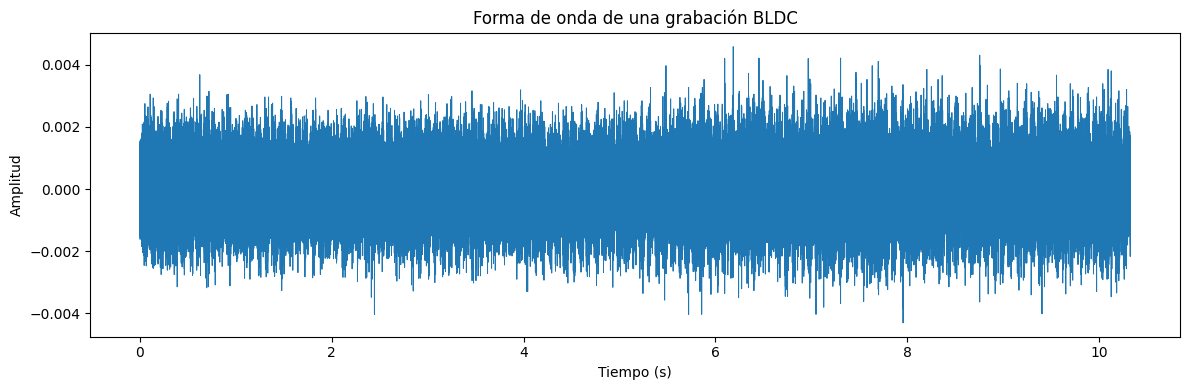

In [8]:
tiempo = np.arange(len(audio_ejemplo)) / sr_ejemplo
plt.figure(figsize=(12, 4))
plt.plot(tiempo, audio_ejemplo, linewidth=0.7)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title("Forma de onda de una grabación BLDC")
plt.tight_layout()
guardar_figura("01_forma_onda_ejemplo.png", "entrega_01")
plt.show()

### ¿Qué representa la forma de onda?

El eje horizontal corresponde al tiempo y el eje vertical a la amplitud. Esta visualización confirma que el archivo se ha convertido correctamente en una señal numérica. La amplitud cambia a lo largo del tiempo y es la materia prima para calcular características acústicas.

## 8. Promedio, desviación estándar y RMS

- **Promedio:** valor medio de las amplitudes. En señales de audio suele estar cerca de cero por la presencia de valores positivos y negativos.
- **Desviación estándar:** mide la dispersión de las amplitudes alrededor del promedio.
- **RMS:** resume la magnitud/energía efectiva de la señal y permite comparar grabaciones mediante un valor por archivo.

In [9]:
media_audio = float(np.mean(audio_ejemplo))
desviacion_audio = float(np.std(audio_ejemplo))
rms_audio = float(np.sqrt(np.mean(audio_ejemplo ** 2)))

print("Promedio de amplitud:", media_audio)
print("Desviación estándar de amplitud:", desviacion_audio)
print("RMS:", rms_audio)

print("\nPromedios generales:")
print("Media de amplitud:", df_audio["media_amplitud"].mean())
print("Desviación de amplitud:", df_audio["desviacion_amplitud"].mean())
print("RMS promedio:", df_audio["rms"].mean())
print("Desviación estándar del RMS:", df_audio["rms"].std())

Promedio de amplitud: 3.376034874236211e-05
Desviación estándar de amplitud: 0.000835022481624037
RMS: 0.0008357046754099429

Promedios generales:
Media de amplitud: 6.947684156583882e-05
Desviación de amplitud: 0.015326522514061613
RMS promedio: 0.015327027231335727
Desviación estándar del RMS: 0.05099907802259468


In [10]:
resumen_rms = df_audio.groupby("condicion")["rms"].agg(["count", "mean", "std", "min", "max"])
display(resumen_rms)

,count,mean,std,min,max
condicion,,,,,
Bearing,7,0.003332,0.002298,0.000836,0.006678
Healthy,22,0.002806,0.002151,0.000749,0.009872
Propeller,14,0.041001,0.085676,0.001547,0.324519


## 9. Detección estadística de valores atípicos mediante IQR

Se conserva el análisis de la primera entrega. Se utiliza el RMS para obtener un valor numérico por grabación.

\[
IQR = Q_3 - Q_1
\]

\[
Límite\ inferior = Q_1 - 1.5(IQR), \qquad
Límite\ superior = Q_3 + 1.5(IQR)
\]

Un registro fuera de los límites se considera atípico **estadísticamente**. Esto no significa automáticamente que el motor esté dañado; la condición mecánica se conoce por las etiquetas del conjunto de datos.

In [11]:
Q1 = df_audio["rms"].quantile(0.25)
Q3 = df_audio["rms"].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df_audio["es_atipico_IQR"] = (
    (df_audio["rms"] < limite_inferior) |
    (df_audio["rms"] > limite_superior)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Cantidad de valores atípicos:", int(df_audio["es_atipico_IQR"].sum()))

Q1: 0.0015669474378228188
Q3: 0.006476338487118483
IQR: 0.004909391049295664
Límite inferior: -0.005797139136120677
Límite superior: 0.013840425061061978
Cantidad de valores atípicos: 4


/tmp/ipykernel_296/345993064.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(datos_box, labels=["Healthy", "Propeller", "Bearing"])


Figura guardada en: reports/figures/entrega_01_exploracion/02_valores_atipicos_IQR.png


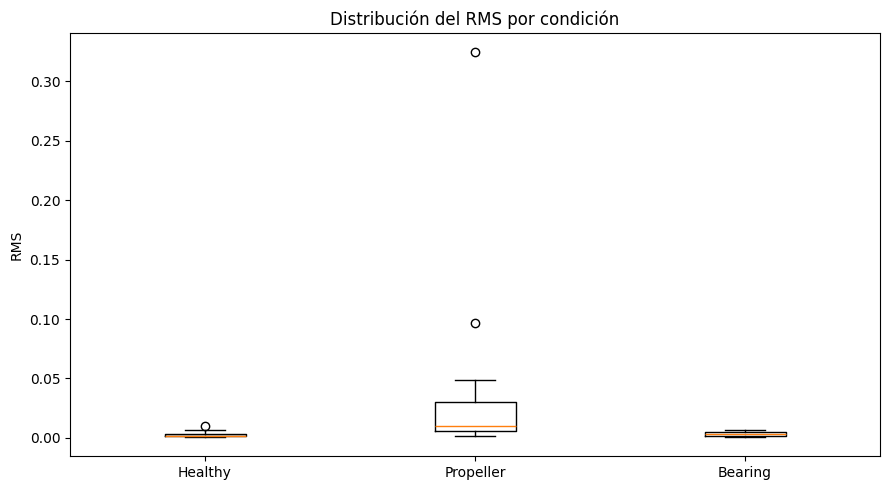

,archivo,condicion,motor,rms
31,1550.wav,Propeller,M1,0.036754
32,1650.wav,Propeller,M1,0.048339
33,1750.wav,Propeller,M1,0.096945
34,1850.wav,Propeller,M1,0.324519


In [12]:
plt.figure(figsize=(9, 5))
datos_box = [df_audio.loc[df_audio["condicion"] == clase, "rms"] for clase in ["Healthy", "Propeller", "Bearing"]]
plt.boxplot(datos_box, labels=["Healthy", "Propeller", "Bearing"])
plt.ylabel("RMS")
plt.title("Distribución del RMS por condición")
plt.tight_layout()
guardar_figura("02_valores_atipicos_IQR.png", "entrega_01")
plt.show()

display(df_audio.loc[df_audio["es_atipico_IQR"], ["archivo", "condicion", "motor", "rms"]])

## 10. Comparación de espectrogramas

El espectrograma muestra cómo se distribuye la energía de la señal en distintas frecuencias a lo largo del tiempo. Se compara un ejemplo `Healthy` con uno `Bearing`, manteniendo la ruta dinámica para no depender de una ruta fija.

Figura guardada en: reports/figures/entrega_01_exploracion/03_comparacion_espectrogramas.png


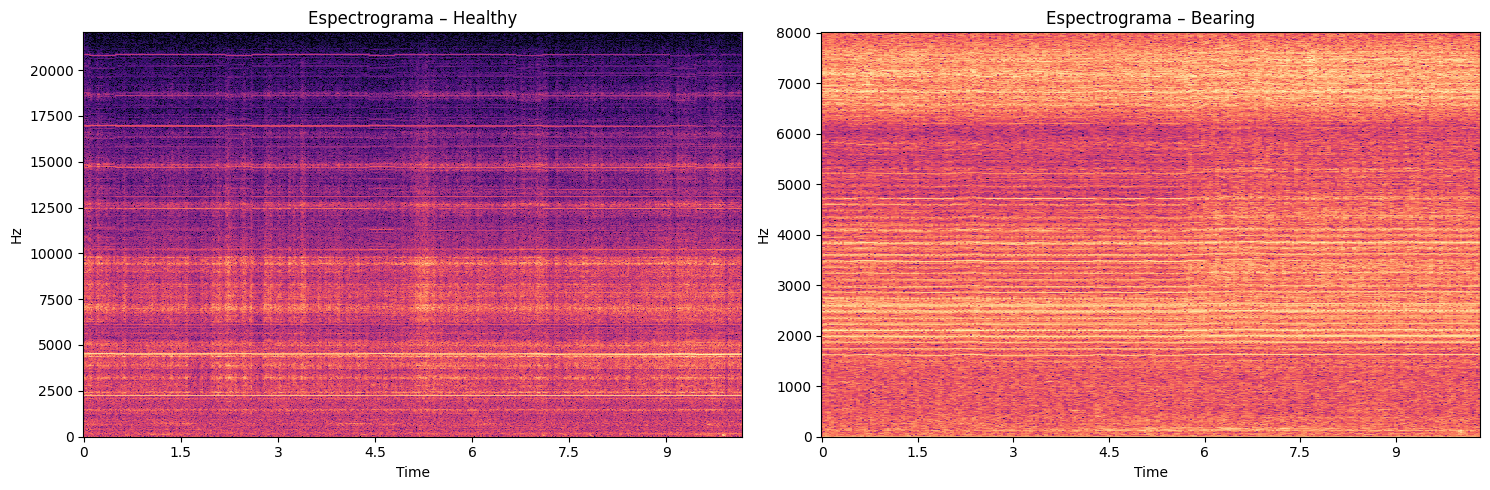

In [13]:
ruta_healthy = df_audio.loc[df_audio["condicion"] == "Healthy", "ruta"].iloc[0]
ruta_bearing = df_audio.loc[df_audio["condicion"] == "Bearing", "ruta"].iloc[0]

audio_healthy, sr_healthy = librosa.load(ruta_healthy, sr=None, mono=True)
audio_bearing, sr_bearing = librosa.load(ruta_bearing, sr=None, mono=True)

D_healthy = librosa.stft(audio_healthy)
S_healthy = librosa.amplitude_to_db(np.abs(D_healthy), ref=np.max)
D_bearing = librosa.stft(audio_bearing)
S_bearing = librosa.amplitude_to_db(np.abs(D_bearing), ref=np.max)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
librosa.display.specshow(S_healthy, sr=sr_healthy, x_axis="time", y_axis="hz", ax=axes[0])
axes[0].set_title("Espectrograma – Healthy")
librosa.display.specshow(S_bearing, sr=sr_bearing, x_axis="time", y_axis="hz", ax=axes[1])
axes[1].set_title("Espectrograma – Bearing")
plt.tight_layout()
guardar_figura("03_comparacion_espectrogramas.png", "entrega_01")
plt.show()

## 11. Melspectrograma: representación acústica para los modelos

Siguiendo la idea del notebook 13, se calcula un melspectrograma. Las bandas Mel resumen la energía de la señal en bandas de frecuencia perceptualmente relacionadas. Esta representación suele ser más compacta que alimentar la señal cruda completa.

Figura guardada en: reports/figures/entrega_01_exploracion/04_melspectrograma.png


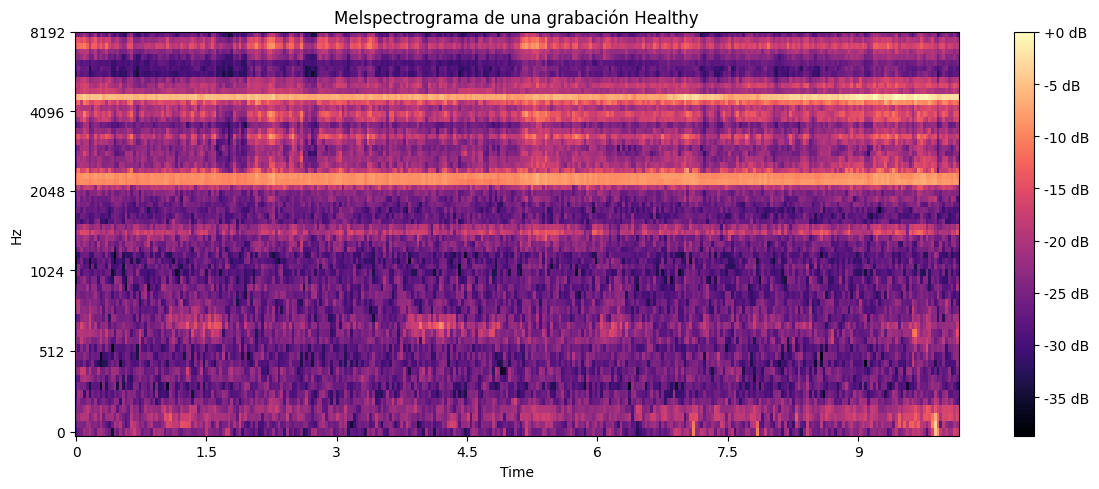

Dimensión del melspectrograma: (64, 318)


In [14]:
# Remuestreo a 16 kHz para que la comparación use la misma escala temporal/frecuencial.
audio_mel, sr_mel = librosa.load(ruta_healthy, sr=16000, mono=True)
mel = librosa.feature.melspectrogram(
    y=audio_mel, sr=sr_mel, n_fft=1024, hop_length=512,
    n_mels=64, power=2.0
)
mel_db = librosa.power_to_db(mel, ref=np.max)

plt.figure(figsize=(12, 5))
librosa.display.specshow(mel_db, sr=sr_mel, hop_length=512, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Melspectrograma de una grabación Healthy")
plt.tight_layout()
guardar_figura("04_melspectrograma.png", "entrega_01")
plt.show()
print("Dimensión del melspectrograma:", mel_db.shape)

## 12. Extracción de características acústicas

Los modelos clásicos necesitan una matriz numérica con el mismo número de columnas para todos los audios. Para cada archivo se calculan:

1. **64 bandas Mel:** media y desviación estándar temporal (128 características).
2. **13 coeficientes MFCC:** media y desviación estándar temporal (26 características).
3. **Descriptores globales:** RMS, centroide espectral, ancho de banda, rolloff, tasa de cruces por cero y flatness; para cada uno se calcula media y desviación estándar (12 características).

En total se generan **166 características acústicas por grabación**. Las columnas `motor`, `rpm`, `archivo` y `condicion` se conservan como metadatos, pero no se entregan como entradas al modelo. Así se evita que el algoritmo use directamente el nombre del motor o las RPM como atajo para predecir la etiqueta.

In [15]:
def extraer_caracteristicas_audio(ruta, sr_objetivo=16000):
    """Convierte un audio en un vector numérico de longitud fija."""
    senal, sr = librosa.load(str(ruta), sr=sr_objetivo, mono=True)
    if senal.size == 0:
        raise ValueError("La señal está vacía")

    caracteristicas = {}

    # Melspectrograma en escala logarítmica: 64 medias + 64 desviaciones.
    mel = librosa.feature.melspectrogram(
        y=senal, sr=sr, n_fft=1024, hop_length=512,
        n_mels=64, power=2.0
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    for prefijo, vector in [
        ("mel_media", np.mean(mel_db, axis=1)),
        ("mel_std", np.std(mel_db, axis=1))
    ]:
        for i, valor in enumerate(vector):
            caracteristicas[f"{prefijo}_{i:02d}"] = float(valor)

    # MFCC: 13 medias + 13 desviaciones.
    mfcc = librosa.feature.mfcc(
        y=senal, sr=sr, n_mfcc=13, n_fft=1024, hop_length=512
    )
    for prefijo, vector in [
        ("mfcc_media", np.mean(mfcc, axis=1)),
        ("mfcc_std", np.std(mfcc, axis=1))
    ]:
        for i, valor in enumerate(vector):
            caracteristicas[f"{prefijo}_{i:02d}"] = float(valor)

    # Estadísticas temporales de descriptores acústicos adicionales.
    descriptores = {
        "rms": librosa.feature.rms(y=senal),
        "centroide": librosa.feature.spectral_centroid(y=senal, sr=sr),
        "ancho_banda": librosa.feature.spectral_bandwidth(y=senal, sr=sr),
        "rolloff": librosa.feature.spectral_rolloff(y=senal, sr=sr),
        "zcr": librosa.feature.zero_crossing_rate(senal),
        "flatness": librosa.feature.spectral_flatness(y=senal)
    }
    for nombre, valores in descriptores.items():
        caracteristicas[f"{nombre}_media"] = float(np.mean(valores))
        caracteristicas[f"{nombre}_std"] = float(np.std(valores))

    return caracteristicas

filas_caracteristicas = []
errores_caracteristicas = []

for _, registro in df_audio.iterrows():
    try:
        fila = {
            "archivo": registro["archivo"],
            "ruta": registro["ruta"],
            "condicion": registro["condicion"],
            "motor": registro["motor"],
            "rpm": registro["rpm"]
        }
        fila.update(extraer_caracteristicas_audio(registro["ruta"]))
        filas_caracteristicas.append(fila)
    except Exception as error:
        errores_caracteristicas.append((registro["archivo"], str(error)))

if errores_caracteristicas:
    print("Archivos omitidos por error:", errores_caracteristicas)

df_caracteristicas = pd.DataFrame(filas_caracteristicas)
columnas_no_predictoras = ["archivo", "ruta", "condicion", "motor", "rpm"]
columnas_caracteristicas = [c for c in df_caracteristicas.columns if c not in columnas_no_predictoras]

print("Grabaciones con características:", len(df_caracteristicas))
print("Número de características por audio:", len(columnas_caracteristicas))
display(df_caracteristicas[["archivo", "condicion", "motor", "rpm"] + columnas_caracteristicas[:5]].head())

Grabaciones con características: 43
Número de características por audio: 166


,archivo,condicion,motor,rpm,mel_media_00,mel_media_01,mel_media_02,mel_media_03,mel_media_04
0,1700.wav,Bearing,M4,1700,-16.258661,-13.665974,-11.269497,-15.774478,-17.434839
1,1750.wav,Bearing,M4,1750,-17.322479,-9.137328,-4.929462,-17.137802,-19.657530
2,1800.wav,Bearing,M4,1800,-20.481049,-12.565145,-6.692142,-18.581802,-21.565042
3,1850.wav,Bearing,M4,1850,-36.322914,-29.790903,-22.124708,-33.575863,-38.198677
4,1900.wav,Bearing,M4,1900,-26.080915,-23.694233,-15.910094,-23.962320,-27.044407


In [16]:
# Limpieza numérica: infinitos se convierten en nulos y se eliminan etiquetas faltantes.
df_caracteristicas = df_caracteristicas.replace([np.inf, -np.inf], np.nan)
df_caracteristicas = df_caracteristicas.dropna(subset=["condicion"]).reset_index(drop=True)
columnas_caracteristicas = [
    c for c in df_caracteristicas.columns
    if c not in columnas_no_predictoras and not df_caracteristicas[c].isna().all()
]

nulos_caracteristicas = int(df_caracteristicas[columnas_caracteristicas].isna().sum().sum())
print("Valores faltantes restantes en características:", nulos_caracteristicas)
print("Valores infinitos restantes:", int(np.isinf(df_caracteristicas[columnas_caracteristicas].to_numpy(dtype=float)).sum()))
print("Los valores faltantes aislados se imputarán con la mediana dentro de cada Pipeline, sin usar datos de validación o prueba.")
print("\nDistribución final de clases:")
display(df_caracteristicas["condicion"].value_counts().to_frame("grabaciones"))

# Exportación de la Entrega 02: características acústicas calculadas por grabación.
ruta_features = RUTA_E2 / "matriz_caracteristicas_audio.csv"
df_caracteristicas.to_csv(ruta_features, index=False, encoding="utf-8-sig")
print("Matriz de características exportada:", ruta_features)


Valores faltantes restantes en características: 0
Valores infinitos restantes: 0
Los valores faltantes aislados se imputarán con la mediana dentro de cada Pipeline, sin usar datos de validación o prueba.

Distribución final de clases:


,grabaciones
condicion,
Healthy,22
Propeller,14
Bearing,7


Matriz de características exportada: /content/data/entrega_02_supervisado/matriz_caracteristicas_audio.csv


# ENTREGA 02 – APRENDIZAJE SUPERVISADO

## 13. Particionado de entrenamiento y prueba (80/20)

Se reserva aproximadamente el 80 % de los archivos para entrenamiento y el 20 % para prueba. Se realiza una partición estratificada manual para conservar al menos dos ejemplos de cada clase en prueba, debido al tamaño reducido de `Bearing` (7 grabaciones). El total continúa siendo 9 archivos de prueba de 43.

La prueba se mantiene separada de la selección de hiperparámetros. Los modelos se ajustan y comparan únicamente con los datos de entrenamiento; el conjunto de prueba se utiliza al final.

In [17]:
def particion_estratificada_indices(y, proporcion_prueba=0.20, minimo_por_clase=2, random_state=42):
    """Partición por clase con tamaño global cercano a la proporción solicitada."""
    y = np.asarray(y)
    rng = np.random.default_rng(random_state)
    indices_train, indices_test = [], []

    for clase in np.unique(y):
        indices_clase = np.where(y == clase)[0].copy()
        rng.shuffle(indices_clase)
        if len(indices_clase) < 2:
            raise ValueError(f"La clase {clase} necesita al menos dos ejemplos.")
        n_test = max(minimo_por_clase, int(round(len(indices_clase) * proporcion_prueba)))
        n_test = min(n_test, len(indices_clase) - 1)
        indices_test.extend(indices_clase[:n_test])
        indices_train.extend(indices_clase[n_test:])

    rng.shuffle(indices_train)
    rng.shuffle(indices_test)
    return np.asarray(indices_train), np.asarray(indices_test)

X = df_caracteristicas[columnas_caracteristicas].copy()
y = df_caracteristicas["condicion"].copy()

indices_train, indices_test = particion_estratificada_indices(
    y, proporcion_prueba=0.20, minimo_por_clase=2, random_state=SEED
)
X_train = X.iloc[indices_train].reset_index(drop=True)
X_test = X.iloc[indices_test].reset_index(drop=True)
y_train = y.iloc[indices_train].reset_index(drop=True)
y_test = y.iloc[indices_test].reset_index(drop=True)

print("Total:", len(X))
print("Entrenamiento:", len(X_train), f"({len(X_train)/len(X):.1%})")
print("Prueba:", len(X_test), f"({len(X_test)/len(X):.1%})")
print("\nClases en entrenamiento:")
display(y_train.value_counts().to_frame("n"))
print("Clases en prueba:")
display(y_test.value_counts().to_frame("n"))

Total: 43
Entrenamiento: 34 (79.1%)
Prueba: 9 (20.9%)

Clases en entrenamiento:


,n
condicion,
Healthy,18
Propeller,11
Bearing,5


Clases en prueba:


,n
condicion,
Healthy,4
Propeller,3
Bearing,2


## 14. Validación cruzada: selección del número de particiones

La guía de la segunda presustentación solicita usar CrossValidation y una curva para elegir el número de iteraciones. En esta adaptación, el número de iteraciones se interpreta como el número de particiones (`n_splits`) de `StratifiedKFold`.

Se comparan 2, 3, 4 y 5 particiones sobre el **conjunto de entrenamiento** mediante un Random Forest de referencia. Se usa **F1-macro** porque promedia el desempeño por clase y evita que la clase mayoritaria domine la comparación. El número de particiones elegido es el que obtiene el mayor promedio de F1-macro; se reporta también su desviación estándar.

In [18]:
minimo_clase_train = int(y_train.value_counts().min())
max_splits = min(5, minimo_clase_train)

modelo_referencia_cv = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("modelo", RandomForestClassifier(
        n_estimators=100, random_state=SEED, class_weight="balanced"
    ))
])

resultados_cv = []
for n_splits in range(2, max_splits + 1):
    cv_actual = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    scores = cross_validate(
        modelo_referencia_cv, X_train, y_train,
        cv=cv_actual, scoring="f1_macro", return_train_score=True
    )
    resultados_cv.append({
        "n_splits": n_splits,
        "F1_macro_validacion": scores["test_score"].mean(),
        "Desviacion_estandar": scores["test_score"].std(),
        "F1_macro_entrenamiento": scores["train_score"].mean()
    })

df_cv = pd.DataFrame(resultados_cv)
display(df_cv)

mejor_fila_cv = df_cv.sort_values(
    ["F1_macro_validacion", "Desviacion_estandar", "n_splits"],
    ascending=[False, True, False]
).iloc[0]
cv_elegido = int(mejor_fila_cv["n_splits"])
cv = StratifiedKFold(n_splits=cv_elegido, shuffle=True, random_state=SEED)

print(f"Número de particiones elegido: {cv_elegido}")
print(f"F1-macro promedio: {mejor_fila_cv['F1_macro_validacion']:.4f}")
print(f"Desviación estándar: {mejor_fila_cv['Desviacion_estandar']:.4f}")

,n_splits,F1_macro_validacion,Desviacion_estandar,F1_macro_entrenamiento
0,2,0.887302,0.112698,1.0
1,3,0.901506,0.070221,1.0
2,4,0.786111,0.215649,1.0
3,5,0.894180,0.149052,1.0


Número de particiones elegido: 3
F1-macro promedio: 0.9015
Desviación estándar: 0.0702


Figura guardada en: reports/figures/entrega_02_supervisado/01_validacion_cruzada.png


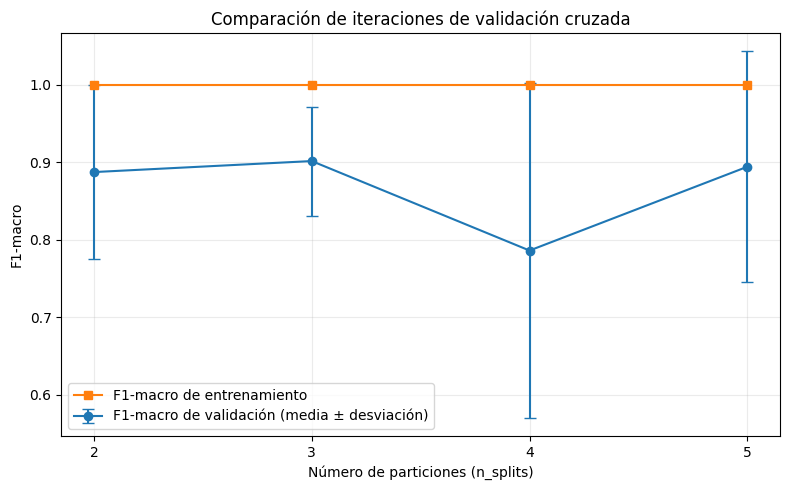

In [19]:
plt.figure(figsize=(8, 5))
plt.errorbar(
    df_cv["n_splits"], df_cv["F1_macro_validacion"],
    yerr=df_cv["Desviacion_estandar"], marker="o", capsize=4,
    label="F1-macro de validación (media ± desviación)"
)
plt.plot(df_cv["n_splits"], df_cv["F1_macro_entrenamiento"], marker="s", label="F1-macro de entrenamiento")
plt.xlabel("Número de particiones (n_splits)")
plt.ylabel("F1-macro")
plt.title("Comparación de iteraciones de validación cruzada")
plt.xticks(df_cv["n_splits"])
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("01_validacion_cruzada.png", "entrega_02")
plt.show()

## 15. Decision Tree – curva para `max_depth`

Se prueba la profundidad máxima del árbol. En cada valor se calcula F1-macro en entrenamiento y validación cruzada. Se selecciona el valor con mayor F1-macro promedio de validación.

,parametro,F1_entrenamiento,F1_validacion,std_validacion
0,1.0,0.555157,0.440336,0.157769
1,2.0,1.000000,0.829630,0.240940
2,3.0,1.000000,0.829630,0.240940
3,4.0,1.000000,0.829630,0.240940
4,5.0,1.000000,0.829630,0.240940
5,NaN,1.000000,0.829630,0.240940


Figura guardada en: reports/figures/entrega_02_supervisado/02_curva_decision_tree.png


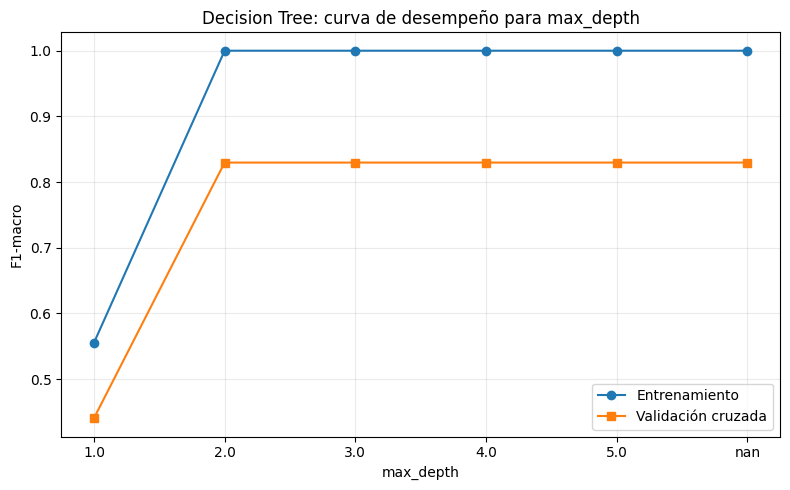

max_depth seleccionado: 2


In [20]:
def crear_pipeline_clasico(estimador):
    return Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
        ("modelo", estimador)
    ])

def evaluar_parametros(valores, crear_estimador):
    resultados = []
    for valor in valores:
        pipeline = crear_pipeline_clasico(crear_estimador(valor))
        scores = cross_validate(
            pipeline, X_train, y_train, cv=cv,
            scoring="f1_macro", return_train_score=True
        )
        resultados.append({
            "parametro": valor,
            "F1_entrenamiento": scores["train_score"].mean(),
            "F1_validacion": scores["test_score"].mean(),
            "std_validacion": scores["test_score"].std()
        })
    return pd.DataFrame(resultados)

profundidades = [1, 2, 3, 4, 5, None]
df_dt_curva = evaluar_parametros(
    profundidades,
    lambda profundidad: DecisionTreeClassifier(
        max_depth=profundidad, random_state=SEED, class_weight="balanced"
    )
)
display(df_dt_curva)

etiquetas_dt = ["None" if v is None else str(v) for v in df_dt_curva["parametro"]]
posiciones = np.arange(len(etiquetas_dt))
plt.figure(figsize=(8, 5))
plt.plot(posiciones, df_dt_curva["F1_entrenamiento"], marker="o", label="Entrenamiento")
plt.plot(posiciones, df_dt_curva["F1_validacion"], marker="s", label="Validación cruzada")
plt.xticks(posiciones, etiquetas_dt)
plt.xlabel("max_depth")
plt.ylabel("F1-macro")
plt.title("Decision Tree: curva de desempeño para max_depth")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("02_curva_decision_tree.png", "entrega_02")
plt.show()

mejor_depth_raw = df_dt_curva.loc[df_dt_curva["F1_validacion"].idxmax(), "parametro"]
mejor_depth = None if pd.isna(mejor_depth_raw) else int(mejor_depth_raw)
print("max_depth seleccionado:", mejor_depth)

## 16. Random Forest – curva para `n_estimators`

Se prueba el número de árboles del bosque. Se mantiene el mismo procedimiento de validación cruzada y el mismo criterio de selección (`F1-macro`).

,parametro,F1_entrenamiento,F1_validacion,std_validacion
0,10,1.0,0.878788,0.110208
1,25,1.0,0.820106,0.156242
2,50,1.0,0.820106,0.156242
3,100,1.0,0.901506,0.070221
4,200,1.0,0.820106,0.156242


Figura guardada en: reports/figures/entrega_02_supervisado/03_curva_random_forest.png


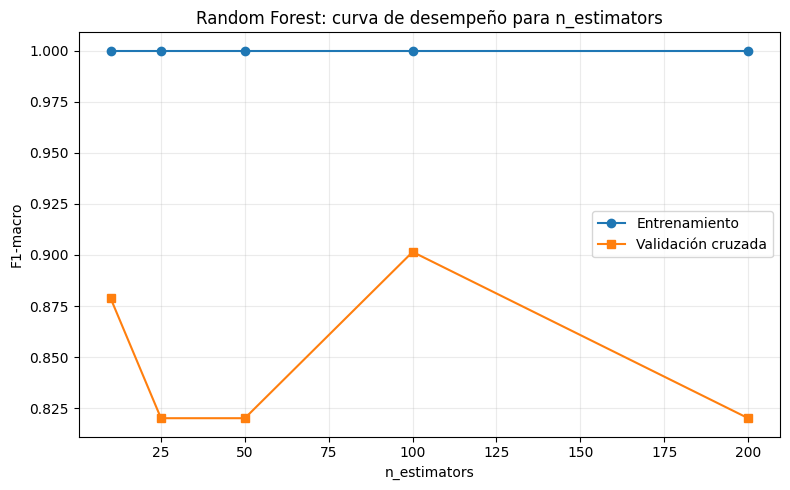

n_estimators seleccionado: 100


In [21]:
numero_arboles = [10, 25, 50, 100, 200]
df_rf_curva = evaluar_parametros(
    numero_arboles,
    lambda n: RandomForestClassifier(
        n_estimators=n, random_state=SEED, class_weight="balanced"
    )
)
display(df_rf_curva)

plt.figure(figsize=(8, 5))
plt.plot(df_rf_curva["parametro"], df_rf_curva["F1_entrenamiento"], marker="o", label="Entrenamiento")
plt.plot(df_rf_curva["parametro"], df_rf_curva["F1_validacion"], marker="s", label="Validación cruzada")
plt.xlabel("n_estimators")
plt.ylabel("F1-macro")
plt.title("Random Forest: curva de desempeño para n_estimators")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("03_curva_random_forest.png", "entrega_02")
plt.show()

mejor_n_estimators = int(df_rf_curva.loc[df_rf_curva["F1_validacion"].idxmax(), "parametro"])
print("n_estimators seleccionado:", mejor_n_estimators)

## 17. SVM – curva para `kernel`

Se comparan los kernels `linear`, `poly` y `rbf`. El escalado se realiza dentro de un `Pipeline`, de modo que durante la validación cada partición aprende su propio escalador sin utilizar información de su pliegue de validación.

,parametro,F1_entrenamiento,F1_validacion,std_validacion
0,linear,1.000000,0.975580,0.034535
1,poly,0.844124,0.812617,0.056775
2,rbf,0.987009,0.875661,0.090799


Figura guardada en: reports/figures/entrega_02_supervisado/04_curva_svm.png


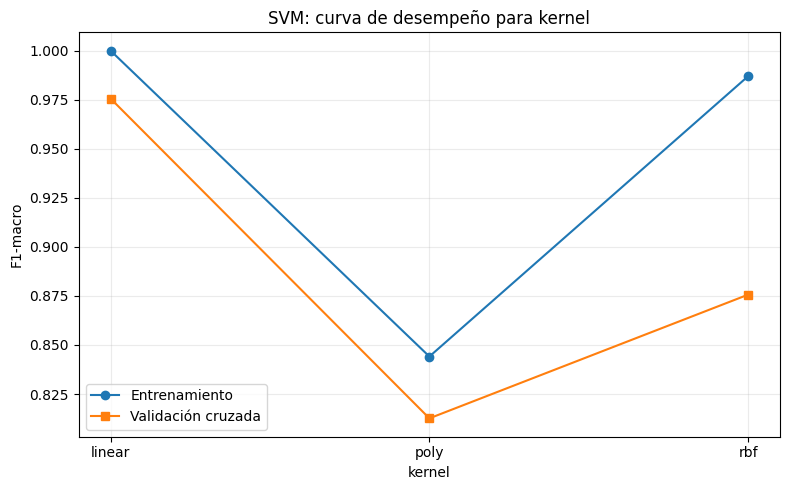

Kernel seleccionado: linear


In [22]:
kernels = ["linear", "poly", "rbf"]
df_svm_curva = evaluar_parametros(
    kernels,
    lambda kernel: SVC(kernel=kernel, class_weight="balanced")
)
display(df_svm_curva)

posiciones = np.arange(len(kernels))
plt.figure(figsize=(8, 5))
plt.plot(posiciones, df_svm_curva["F1_entrenamiento"], marker="o", label="Entrenamiento")
plt.plot(posiciones, df_svm_curva["F1_validacion"], marker="s", label="Validación cruzada")
plt.xticks(posiciones, kernels)
plt.xlabel("kernel")
plt.ylabel("F1-macro")
plt.title("SVM: curva de desempeño para kernel")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("04_curva_svm.png", "entrega_02")
plt.show()

mejor_kernel = str(df_svm_curva.loc[df_svm_curva["F1_validacion"].idxmax(), "parametro"])
print("Kernel seleccionado:", mejor_kernel)

## 18. Entrenamiento final de los tres modelos clásicos

Con los hiperparámetros seleccionados por validación cruzada, se ajustan los modelos utilizando todo el conjunto de entrenamiento. El conjunto de prueba continúa reservado para la comparación final.

In [23]:
modelo_dt = crear_pipeline_clasico(DecisionTreeClassifier(
    max_depth=mejor_depth, random_state=SEED, class_weight="balanced"
))
modelo_rf = crear_pipeline_clasico(RandomForestClassifier(
    n_estimators=mejor_n_estimators, random_state=SEED, class_weight="balanced"
))
modelo_svm = crear_pipeline_clasico(SVC(
    kernel=mejor_kernel, class_weight="balanced"
))

modelos_clasicos = {
    "Decision Tree": modelo_dt,
    "Random Forest": modelo_rf,
    "SVM": modelo_svm
}

for nombre, modelo in modelos_clasicos.items():
    modelo.fit(X_train, y_train)
    print(nombre, "entrenado.")

print("\nHiperparámetros seleccionados:")
print("Decision Tree max_depth:", mejor_depth)
print("Random Forest n_estimators:", mejor_n_estimators)
print("SVM kernel:", mejor_kernel)

Decision Tree entrenado.
Random Forest entrenado.
SVM entrenado.

Hiperparámetros seleccionados:
Decision Tree max_depth: 2
Random Forest n_estimators: 100
SVM kernel: linear


## 19. Deep Learning – perceptrón multicapa (MLP)

Siguiendo la guía de la segunda presustentación, se entrenarán tres arquitecturas:

- **3 capas ocultas:** 64, 128, 128 neuronas.
- **6 capas ocultas:** 64, 64, 128, 128, 256, 256 neuronas.
- **10 capas ocultas:** 128 neuronas en cada capa.

Para cada arquitectura se ejecuta un experimento con **5, 10, 50 y 100 épocas** (12 experimentos en total). La salida tiene 3 neuronas con `softmax`, una por cada condición.

Como el dataset tiene pocos registros, se incorpora `Dropout` como regularización y se calcula un conjunto de validación interno a partir del entrenamiento. La arquitectura y el número de épocas se seleccionan por F1-macro de validación; el conjunto de prueba no interviene en esa elección.

In [24]:
# Separación interna entrenamiento/validación para seleccionar la red y las épocas.
indices_nn_train, indices_nn_val = particion_estratificada_indices(
    y_train, proporcion_prueba=0.25, minimo_por_clase=2, random_state=SEED + 1
)
X_nn_train = X_train.iloc[indices_nn_train].copy()
X_nn_val = X_train.iloc[indices_nn_val].copy()
y_nn_train = y_train.iloc[indices_nn_train].copy()
y_nn_val = y_train.iloc[indices_nn_val].copy()

# Imputación y escalado: se ajustan solo con la parte de entrenamiento interna.
imputador_nn = SimpleImputer(strategy="median")
escalador_nn = StandardScaler()
X_nn_train_imp = imputador_nn.fit_transform(X_nn_train)
X_nn_val_imp = imputador_nn.transform(X_nn_val)
X_test_imp_nn = imputador_nn.transform(X_test)

X_nn_train_z = escalador_nn.fit_transform(X_nn_train_imp)
X_nn_val_z = escalador_nn.transform(X_nn_val_imp)
X_test_z_nn = escalador_nn.transform(X_test_imp_nn)

codificador = LabelEncoder()
y_nn_train_enc = codificador.fit_transform(y_nn_train)
y_nn_val_enc = codificador.transform(y_nn_val)
y_test_enc_dl = codificador.transform(y_test)
n_clases = len(codificador.classes_)

# One-hot encoding, como en el ejemplo del notebook 13.
y_nn_train_ohe = keras.utils.to_categorical(y_nn_train_enc, num_classes=n_clases)
y_nn_val_ohe = keras.utils.to_categorical(y_nn_val_enc, num_classes=n_clases)

# Compensación de la clase minoritaria mediante pesos por muestra.
pesos_clase = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(n_clases),
    y=y_nn_train_enc
)
pesos_por_clase = dict(enumerate(pesos_clase))
pesos_muestra = np.array([pesos_por_clase[int(clase)] for clase in y_nn_train_enc])

print("Clases de salida:", list(codificador.classes_))
print("Entrada de la red:", X_nn_train_z.shape[1], "características")
print("Entrenamiento interno:", X_nn_train_z.shape[0], "audios")
print("Validación interna:", X_nn_val_z.shape[0], "audios")

Clases de salida: ['Bearing', 'Healthy', 'Propeller']
Entrada de la red: 166 características
Entrenamiento interno: 25 audios
Validación interna: 9 audios


In [25]:
def construir_mlp(numero_entradas, unidades_ocultas, numero_clases):
    capas = [keras.layers.Input(shape=(numero_entradas,))]
    for neuronas in unidades_ocultas:
        capas.append(keras.layers.Dense(
            neuronas, activation="relu",
            kernel_regularizer=keras.regularizers.l2(1e-4)
        ))
        capas.append(keras.layers.Dropout(0.20))
    capas.append(keras.layers.Dense(numero_clases, activation="softmax"))

    modelo = keras.Sequential(capas)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

arquitecturas = {
    "MLP 3 capas (64-128-128)": [64, 128, 128],
    "MLP 6 capas (64-64-128-128-256-256)": [64, 64, 128, 128, 256, 256],
    "MLP 10 capas (128 x 10)": [128] * 10
}
epocas_experimentos = [5, 10, 50, 100]

resultados_dl = []
mejor_f1_dl = -1.0
mejor_config_dl = None
mejores_pesos_dl = None

for nombre_arquitectura, unidades in arquitecturas.items():
    for epocas in epocas_experimentos:
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        modelo = construir_mlp(X_nn_train_z.shape[1], unidades, n_clases)

        historial = modelo.fit(
            X_nn_train_z, y_nn_train_ohe,
            epochs=epocas,
            batch_size=8,
            verbose=0,
            validation_data=(X_nn_val_z, y_nn_val_ohe),
            sample_weight=pesos_muestra
        )

        probabilidades_val = modelo.predict(X_nn_val_z, verbose=0)
        pred_val = np.argmax(probabilidades_val, axis=1)
        f1_val = f1_score(
            y_nn_val_enc, pred_val, labels=np.arange(n_clases),
            average="macro", zero_division=0
        )
        accuracy_val = accuracy_score(y_nn_val_enc, pred_val)

        resultados_dl.append({
            "arquitectura": nombre_arquitectura,
            "epocas": epocas,
            "accuracy_validacion": accuracy_val,
            "F1_macro_validacion": f1_val,
            "loss_entrenamiento_final": historial.history["loss"][-1],
            "loss_validacion_final": historial.history["val_loss"][-1]
        })

        if f1_val > mejor_f1_dl:
            mejor_f1_dl = f1_val
            mejor_config_dl = (nombre_arquitectura, unidades.copy(), epocas)
            mejores_pesos_dl = [peso.copy() for peso in modelo.get_weights()]

        print(f"{nombre_arquitectura} | épocas={epocas} | F1-macro validación={f1_val:.4f}")

df_resultados_dl = pd.DataFrame(resultados_dl)
display(df_resultados_dl.sort_values("F1_macro_validacion", ascending=False))

print("\nMejor combinación seleccionada:")
print("Arquitectura:", mejor_config_dl[0])
print("Capas ocultas:", mejor_config_dl[1])
print("Épocas:", mejor_config_dl[2])
print("F1-macro validación:", mejor_f1_dl)

MLP 3 capas (64-128-128) | épocas=5 | F1-macro validación=0.7778
MLP 3 capas (64-128-128) | épocas=10 | F1-macro validación=1.0000
MLP 3 capas (64-128-128) | épocas=50 | F1-macro validación=1.0000
MLP 3 capas (64-128-128) | épocas=100 | F1-macro validación=1.0000


MLP 6 capas (64-64-128-128-256-256) | épocas=5 | F1-macro validación=0.5000


MLP 6 capas (64-64-128-128-256-256) | épocas=10 | F1-macro validación=0.5000
MLP 6 capas (64-64-128-128-256-256) | épocas=50 | F1-macro validación=1.0000
MLP 6 capas (64-64-128-128-256-256) | épocas=100 | F1-macro validación=1.0000
MLP 10 capas (128 x 10) | épocas=5 | F1-macro validación=0.2222
MLP 10 capas (128 x 10) | épocas=10 | F1-macro validación=0.5000
MLP 10 capas (128 x 10) | épocas=50 | F1-macro validación=1.0000
MLP 10 capas (128 x 10) | épocas=100 | F1-macro validación=1.0000


,arquitectura,epocas,accuracy_validacion,F1_macro_validacion,loss_entrenamiento_final,loss_validacion_final
1,MLP 3 capas (64-128-128),10,1.000000,1.000000,0.285904,0.168978
2,MLP 3 capas (64-128-128),50,1.000000,1.000000,0.030879,0.030109
3,MLP 3 capas (64-128-128),100,1.000000,1.000000,0.028946,0.028820
7,MLP 6 capas (64-64-128-128-256-256),100,1.000000,1.000000,0.072495,0.072172
10,MLP 10 capas (128 x 10),50,1.000000,1.000000,0.261626,0.117967
6,MLP 6 capas (64-64-128-128-256-256),50,1.000000,1.000000,0.075389,0.074212
11,MLP 10 capas (128 x 10),100,1.000000,1.000000,0.112819,0.112722
0,MLP 3 capas (64-128-128),5,0.777778,0.777778,0.608882,0.508561
4,MLP 6 capas (64-64-128-128-256-256),5,0.555556,0.500000,0.937885,0.928289
5,MLP 6 capas (64-64-128-128-256-256),10,0.555556,0.500000,0.718668,0.725199



Mejor combinación seleccionada:
Arquitectura: MLP 3 capas (64-128-128)
Capas ocultas: [64, 128, 128]
Épocas: 10
F1-macro validación: 1.0


### Curvas de los experimentos de Deep Learning

La tabla permite comparar cada arquitectura y cada cantidad de épocas. En las siguientes gráficas se visualiza el F1-macro de validación por época seleccionada para cada arquitectura. El mejor punto determina la configuración final de la red.

Figura guardada en: reports/figures/entrega_02_supervisado/05_curvas_deep_learning.png


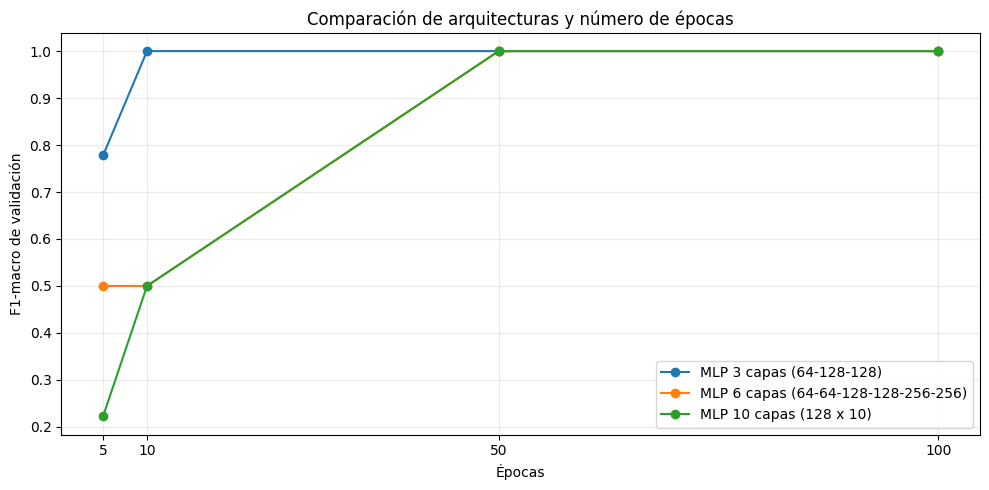

In [26]:
plt.figure(figsize=(10, 5))
for nombre in arquitecturas.keys():
    subset = df_resultados_dl[df_resultados_dl["arquitectura"] == nombre].sort_values("epocas")
    plt.plot(subset["epocas"], subset["F1_macro_validacion"], marker="o", label=nombre)
plt.xlabel("Épocas")
plt.ylabel("F1-macro de validación")
plt.title("Comparación de arquitecturas y número de épocas")
plt.xticks(epocas_experimentos)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("05_curvas_deep_learning.png", "entrega_02")
plt.show()

## 20. Evaluación final sobre el conjunto de prueba

Se reconstruye la mejor arquitectura y se recuperan sus pesos seleccionados con validación interna. Después se evalúa una sola vez sobre los audios de prueba. Se reportan exactitud, precisión macro, recall macro, F1-macro y balanced accuracy.

In [27]:
# Reconstrucción de la mejor red con los pesos de su experimento seleccionado.
keras.backend.clear_session()
modelo_dl = construir_mlp(X_nn_train_z.shape[1], mejor_config_dl[1], n_clases)
modelo_dl.set_weights(mejores_pesos_dl)
modelo_dl.summary()

probabilidades_test_dl = modelo_dl.predict(X_test_z_nn, verbose=0)
predicciones_test_dl = codificador.inverse_transform(np.argmax(probabilidades_test_dl, axis=1))

predicciones = {
    "Decision Tree": modelo_dt.predict(X_test),
    "Random Forest": modelo_rf.predict(X_test),
    "SVM": modelo_svm.predict(X_test),
    "Deep Learning": predicciones_test_dl
}

filas_metricas = []
for nombre, pred in predicciones.items():
    filas_metricas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "Balanced_accuracy": balanced_accuracy_score(y_test, pred)
    })

metricas_finales = pd.DataFrame(filas_metricas).sort_values("F1-macro", ascending=False).reset_index(drop=True)
display(metricas_finales)

print("Configuración de Deep Learning evaluada:", mejor_config_dl[0], "| épocas:", mejor_config_dl[2])

# Exportación de métricas y modelos de la Entrega 02.
metricas_finales.to_csv(RUTA_E2 / "metricas_modelos_supervisados.csv", index=False, encoding="utf-8-sig")
metricas_finales.to_csv(RUTA_TABLAS_E2 / "metricas_modelos_supervisados.csv", index=False, encoding="utf-8-sig")
try:
    import joblib
    joblib.dump(modelos_clasicos, RUTA_MODELOS_SUP / "modelos_clasicos.joblib")
    if "modelo_dl" in globals() and TF_DISPONIBLE:
        modelo_dl.save(RUTA_MODELOS_SUP / "modelo_mlp.keras")
    print("Modelos supervisados guardados en:", RUTA_MODELOS_SUP)
except Exception as error:
    warnings.warn(f"No fue posible guardar los modelos clásicos: {error}")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        10,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,907 (140.26 KB)

 Trainable params: 35,907 (140.26 KB)

 Non-trainable params: 0 (0.00 B)

,Modelo,Accuracy,Precision_macro,Recall_macro,F1-macro,Balanced_accuracy
0,SVM,1.000000,1.000000,1.000000,1.000000,1.000000
1,Decision Tree,0.888889,0.933333,0.833333,0.851852,0.833333
2,Random Forest,0.888889,0.933333,0.833333,0.851852,0.833333
3,Deep Learning,0.888889,0.933333,0.833333,0.851852,0.833333


Configuración de Deep Learning evaluada: MLP 3 capas (64-128-128) | épocas: 10
Modelos supervisados guardados en: /content/models/supervisados


## 21. Barplot comparativo de desempeño

La segunda presustentación solicita reportar el desempeño de Decision Tree, Random Forest, SVM y Deep Learning con un gráfico de barras. Se comparan `Accuracy` y `F1-macro`; este último es especialmente importante porque considera el desempeño de cada clase con el mismo peso.

Figura guardada en: reports/figures/entrega_02_supervisado/06_comparacion_modelos.png


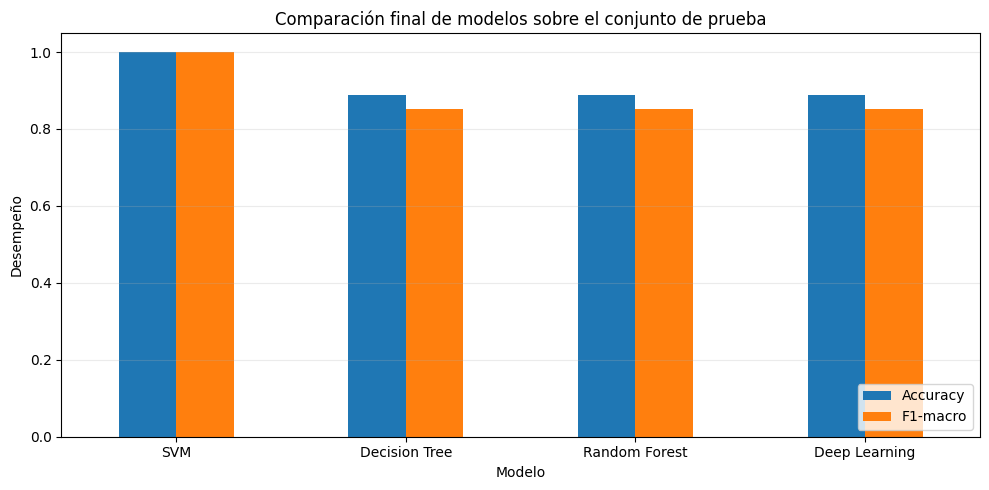

In [28]:
metricas_grafico = metricas_finales.set_index("Modelo")[["Accuracy", "F1-macro"]]
ax = metricas_grafico.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
ax.set_title("Comparación final de modelos sobre el conjunto de prueba")
ax.set_ylabel("Desempeño")
ax.set_xlabel("Modelo")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
guardar_figura("06_comparacion_modelos.png", "entrega_02")
plt.show()

## 22. Matrices de confusión

La matriz de confusión muestra qué clases fueron clasificadas correctamente y cuáles se confundieron. En un conjunto de prueba tan pequeño, cada error representa una fracción importante del total; por eso se debe interpretar junto con las métricas y el tamaño del dataset.

Figura guardada en: reports/figures/entrega_02_supervisado/07_matrices_confusion.png


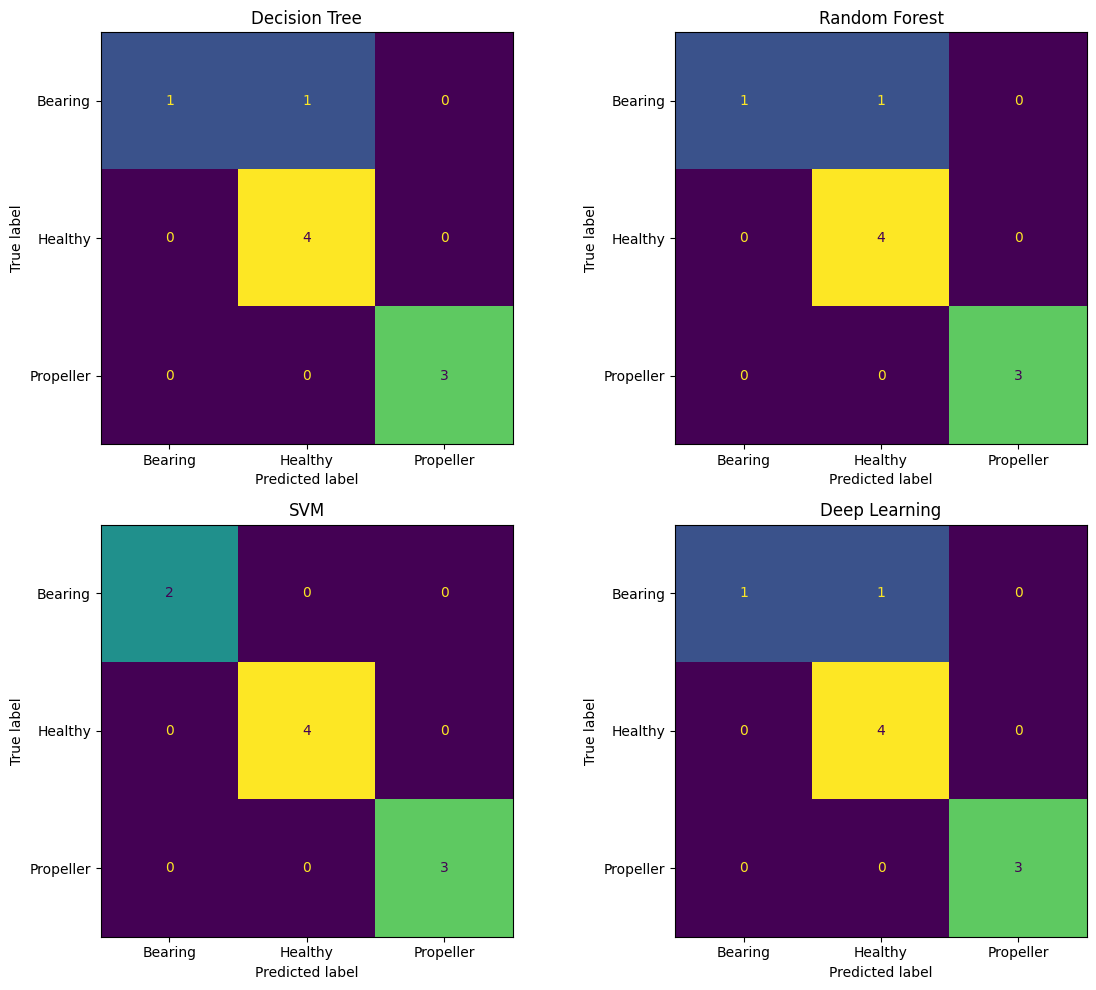

In [29]:
orden_clases = list(codificador.classes_)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (nombre, pred) in zip(axes.ravel(), predicciones.items()):
    cm = confusion_matrix(y_test, pred, labels=orden_clases)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=orden_clases)
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(nombre)
plt.tight_layout()
guardar_figura("07_matrices_confusion.png", "entrega_02")
plt.show()

# ENTREGA FINAL – APRENDIZAJE NO SUPERVISADO

## 24. Preparación de datos para clustering

En esta fase se toma la matriz numérica de características acústicas y se agrupan grabaciones por similitud. A diferencia de la fase supervisada, **no se utiliza `condicion` para ajustar el escalador, PCA, K-means ni DBSCAN**. La etiqueta se conserva aparte y se incorpora únicamente al final para interpretar los clústeres.

**Secuencia solicitada:**

1. Imputar valores ausentes y estandarizar con `StandardScaler`.
2. Reducir las 166 características a dos componentes mediante PCA.
3. Aplicar K-means con `n_clusters` igual al número de condiciones conocidas (tres).
4. Ajustar DBSCAN explorando `eps` y `min_samples` con la curva de distancias k-vecinos y una búsqueda reproducible.
5. Graficar los grupos sobre el plano PCA y revisar una proyección t-SNE opcional.

> **Decisión metodológica:** para seguir la secuencia de la guía, K-means y DBSCAN se ajustan sobre las dos componentes PCA. Esto facilita comparar y visualizar los grupos, pero implica que el clustering se realiza sobre una proyección que puede descartar información. Se reportará la varianza explicada para que esa limitación quede cuantificada.


Número de grabaciones: 43
Número de características originales: 166
Media global aproximada después de escalar: -1.4184973360299e-17
Desviación estándar global aproximada: 1.0
Varianza explicada por PC1: 61.68%
Varianza explicada por PC2: 10.98%
Varianza explicada acumulada (2 componentes): 72.66%
Figura guardada en: reports/figures/entrega_final/01_pca_etiquetas_referencia.png


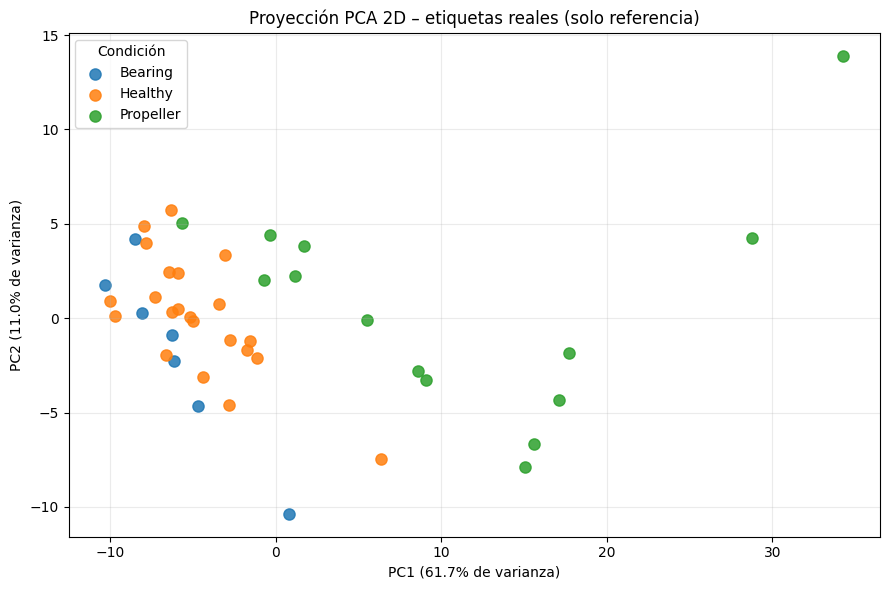

In [30]:
# 24.1 Imputación y escalado
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score
)
import joblib

# La matriz X_unsup solo contiene columnas numéricas de características; se excluyen
# archivo, ruta, motor, rpm y, especialmente, la etiqueta real 'condicion'.
X_unsup = df_caracteristicas[columnas_caracteristicas].select_dtypes(include=[np.number]).copy()
y_referencia = df_caracteristicas["condicion"].astype(str).reset_index(drop=True)
metadatos_unsup = df_caracteristicas[["archivo", "condicion", "motor", "rpm"]].reset_index(drop=True)

imputador_unsup = SimpleImputer(strategy="median")
X_imputado = imputador_unsup.fit_transform(X_unsup)

# StandardScaler: centra cada característica en media 0 y desviación estándar 1.
# Es adecuado aquí porque K-means y DBSCAN dependen de distancias euclidianas.
escalador_unsup = StandardScaler()
X_escalado = escalador_unsup.fit_transform(X_imputado)

print("Número de grabaciones:", X_escalado.shape[0])
print("Número de características originales:", X_escalado.shape[1])
print("Media global aproximada después de escalar:", float(np.mean(X_escalado)))
print("Desviación estándar global aproximada:", float(np.std(X_escalado)))

# Guardar la matriz escalada para que esta etapa sea auditable y reproducible.
df_escalado = pd.DataFrame(X_escalado, columns=columnas_caracteristicas)
df_escalado.insert(0, "archivo", metadatos_unsup["archivo"])
df_escalado.to_csv(RUTA_E3 / "matriz_escalada_standard_scaler.csv", index=False, encoding="utf-8-sig")

# 24.2 Reducción PCA a dos componentes
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_escalado)
varianza_pca = pca_2d.explained_variance_ratio_
varianza_acumulada = float(varianza_pca.sum())

print("Varianza explicada por PC1:", f"{varianza_pca[0]:.2%}")
print("Varianza explicada por PC2:", f"{varianza_pca[1]:.2%}")
print("Varianza explicada acumulada (2 componentes):", f"{varianza_acumulada:.2%}")

# El DataFrame conserva la etiqueta solo para inspección visual y evaluación posterior.
df_pca = metadatos_unsup.copy()
df_pca["PC1"] = X_pca[:, 0]
df_pca["PC2"] = X_pca[:, 1]
df_pca.to_csv(RUTA_E3 / "coordenadas_pca_2_componentes.csv", index=False, encoding="utf-8-sig")

# 24.3 Gráfica inicial: etiquetas de referencia sobre el plano PCA
plt.figure(figsize=(9, 6))
for clase in sorted(y_referencia.unique()):
    mascara = (y_referencia == clase).to_numpy()
    plt.scatter(X_pca[mascara, 0], X_pca[mascara, 1], label=clase, alpha=0.85, s=65)
plt.xlabel(f"PC1 ({varianza_pca[0]:.1%} de varianza)")
plt.ylabel(f"PC2 ({varianza_pca[1]:.1%} de varianza)")
plt.title("Proyección PCA 2D – etiquetas reales (solo referencia)")
plt.legend(title="Condición")
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("01_pca_etiquetas_referencia.png", "final")
plt.show()


## 25. K-means sobre las dos componentes PCA

Se define `n_clusters` como el número de condiciones conocidas en el dataset. En este caso son tres (`Healthy`, `Propeller` y `Bearing`). Esta elección sigue la instrucción de la entrega, pero no significa que K-means conozca las clases: el algoritmo recibe únicamente las coordenadas PCA.



Número de clústeres configurado: 3
Tamaños obtenidos:
0    32
1     2
2     9
Name: count, dtype: int64
Silhouette (interno): 0.624
Davies-Bouldin (interno; menor suele ser mejor): 0.5403
ARI frente a las etiquetas reales (evaluación posterior): 0.2316
NMI frente a las etiquetas reales (evaluación posterior): 0.2427
Figura guardada en: reports/figures/entrega_final/02_kmeans_pca.png


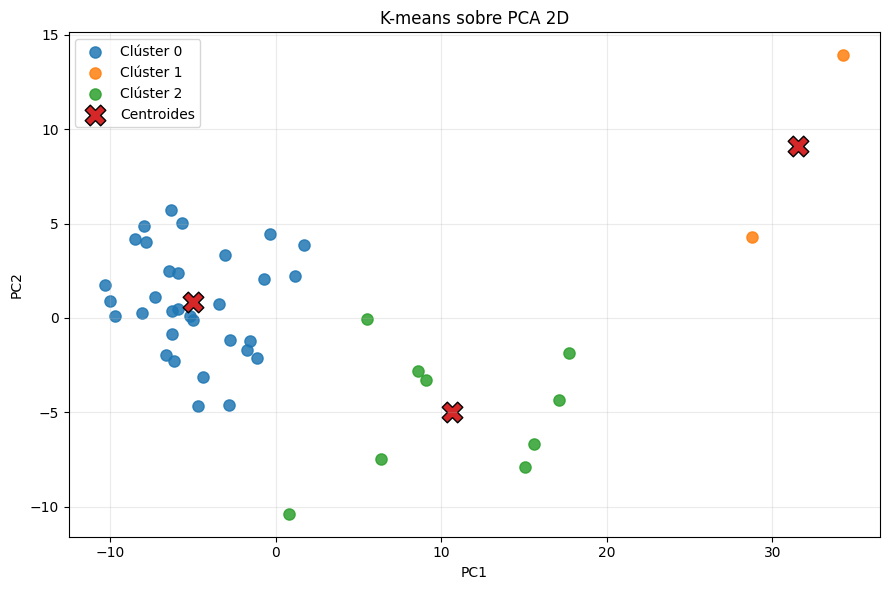

In [31]:
numero_clases_dataset = int(y_referencia.nunique())
modelo_kmeans = KMeans(
    n_clusters=numero_clases_dataset,
    random_state=SEED,
    n_init=20
)
clusters_kmeans = modelo_kmeans.fit_predict(X_pca)

silhouette_kmeans = silhouette_score(X_pca, clusters_kmeans) if len(np.unique(clusters_kmeans)) > 1 else np.nan
db_kmeans = davies_bouldin_score(X_pca, clusters_kmeans) if len(np.unique(clusters_kmeans)) > 1 else np.nan
ari_kmeans = adjusted_rand_score(y_referencia, clusters_kmeans)
nmi_kmeans = normalized_mutual_info_score(y_referencia, clusters_kmeans)

print("Número de clústeres configurado:", numero_clases_dataset)
print("Tamaños obtenidos:")
print(pd.Series(clusters_kmeans).value_counts().sort_index())
print("Silhouette (interno):", round(float(silhouette_kmeans), 4))
print("Davies-Bouldin (interno; menor suele ser mejor):", round(float(db_kmeans), 4))
print("ARI frente a las etiquetas reales (evaluación posterior):", round(float(ari_kmeans), 4))
print("NMI frente a las etiquetas reales (evaluación posterior):", round(float(nmi_kmeans), 4))

# La numeración 0, 1, 2 es arbitraria; no equivale a una clase específica.
df_kmeans = df_pca.copy()
df_kmeans["cluster_kmeans"] = clusters_kmeans
df_kmeans.to_csv(RUTA_E3 / "resultados_kmeans.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(9, 6))
for cluster in sorted(np.unique(clusters_kmeans)):
    mascara = clusters_kmeans == cluster
    plt.scatter(X_pca[mascara, 0], X_pca[mascara, 1], label=f"Clúster {cluster}", alpha=0.85, s=65)
centros = modelo_kmeans.cluster_centers_
plt.scatter(centros[:, 0], centros[:, 1], marker="X", s=220, edgecolor="black", label="Centroides")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-means sobre PCA 2D")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("02_kmeans_pca.png", "final")
plt.show()


## 26. Búsqueda y aplicación de DBSCAN

DBSCAN necesita dos parámetros:

- **`min_samples`:** cantidad mínima de puntos en la vecindad para que un punto sea considerado núcleo. Como la entrada tiene dos dimensiones PCA, se usa `D + 1 = 3` como punto de partida y se prueban valores cercanos (3, 4, 5 y 6). La muestra es pequeña (43 audios), así que no se fija un valor grande sin comprobar el efecto.
- **`eps`:** radio de vecindad. No se elige al azar: para cada `min_samples` se calcula la distancia al k-ésimo vecino y se prueban varios cuantiles de esas distancias. La curva k-distancias sirve para localizar cambios de pendiente o “codos”.

La búsqueda selecciona, entre las configuraciones que producen al menos dos clústeres, la que maximiza `silhouette` en puntos no considerados ruido, penalizando una proporción alta de ruido. **Las etiquetas reales no participan en esta selección.** Si ninguna combinación forma al menos dos clústeres, se informa que DBSCAN no encuentra una estructura de densidad defendible con los parámetros explorados; no se fuerza una conclusión.



Mejores configuraciones viables (sin usar las etiquetas reales):
 min_samples      eps  n_clusters  n_ruido  proporcion_ruido  silhouette_sin_ruido  score_seleccion
           3 3.539517           2        7          0.162791              0.763343         0.722646
           4 4.954570           2        4          0.093023              0.661796         0.638540
           4 5.258539           2        3          0.069767              0.631742         0.614300
           3 5.113179           2        3          0.069767              0.631742         0.614300
           4 6.513728           2        2          0.046512              0.616200         0.604572
           3 6.635013           2        2          0.046512              0.616200         0.604572
           3 4.606222           3        4          0.093023              0.579048         0.555792
           3 2.414286           2       12          0.279070              0.397889         0.328121
           4 2.646092           2  

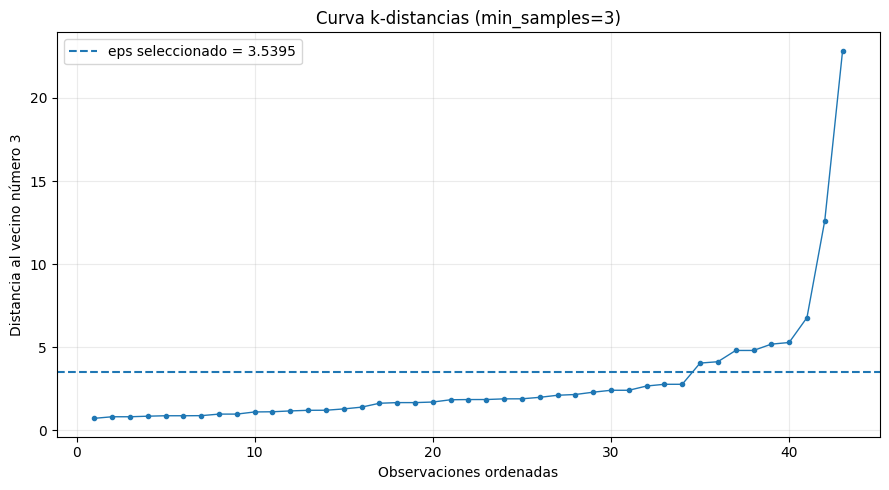

Clústeres DBSCAN (sin contar ruido): 2
Puntos clasificados como ruido (-1): 7 (16.3%)
Silhouette solo en puntos no-ruido: 0.7633432156825132
ARI frente a las etiquetas reales (evaluación posterior): 0.2234
NMI frente a las etiquetas reales (evaluación posterior): 0.2517
Figura guardada en: reports/figures/entrega_final/04_dbscan_pca.png


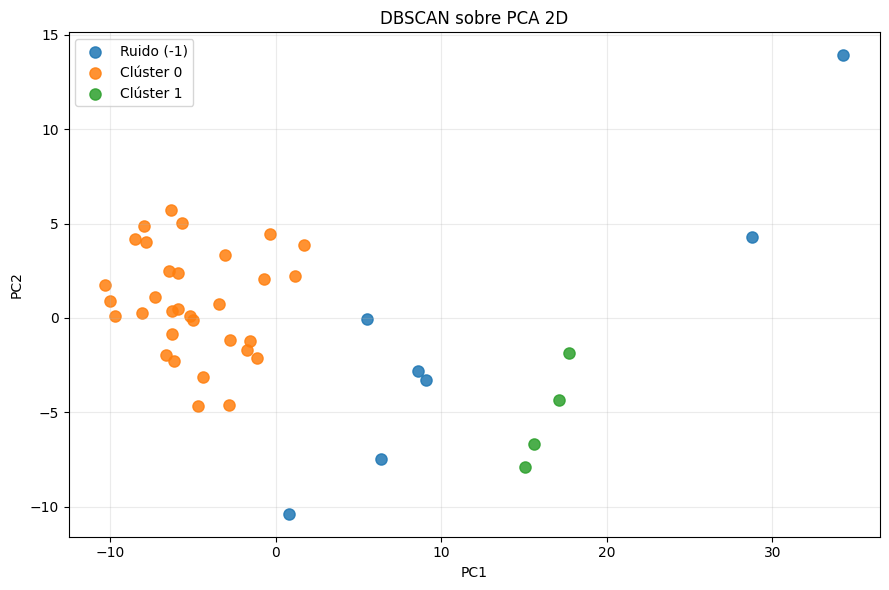

In [32]:
# 26.1 Búsqueda reproducible de min_samples y eps mediante k-distancias
n_muestras = X_pca.shape[0]
min_samples_candidatos = [m for m in [3, 4, 5, 6] if m < n_muestras]
cuantiles_eps = [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.98]
filas_busqueda_dbscan = []
curvas_kdistancias = {}

for min_samples in min_samples_candidatos:
    vecinos = NearestNeighbors(n_neighbors=min_samples, metric="euclidean")
    vecinos.fit(X_pca)
    distancias, _ = vecinos.kneighbors(X_pca)
    k_distancias = np.sort(distancias[:, -1])
    curvas_kdistancias[min_samples] = k_distancias

    eps_candidatos = np.unique(np.quantile(k_distancias, cuantiles_eps))
    eps_candidatos = [float(eps) for eps in eps_candidatos if np.isfinite(eps) and eps > 0]

    for eps in eps_candidatos:
        etiquetas_db = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean").fit_predict(X_pca)
        clusters_validos = sorted(set(etiquetas_db) - {-1})
        n_clusters_db = len(clusters_validos)
        mascara_core = etiquetas_db != -1
        n_ruido = int((~mascara_core).sum())
        proporcion_ruido = n_ruido / n_muestras
        silhouette_db = np.nan
        if n_clusters_db >= 2 and mascara_core.sum() > n_clusters_db:
            try:
                silhouette_db = float(silhouette_score(X_pca[mascara_core], etiquetas_db[mascara_core]))
            except Exception:
                pass

        # Puntaje interno: silhouette de los puntos agrupados menos penalización por ruido.
        score_busqueda = (
            silhouette_db - 0.25 * proporcion_ruido
            if np.isfinite(silhouette_db) else np.nan
        )
        filas_busqueda_dbscan.append({
            "min_samples": min_samples,
            "eps": eps,
            "n_clusters": n_clusters_db,
            "n_ruido": n_ruido,
            "proporcion_ruido": proporcion_ruido,
            "silhouette_sin_ruido": silhouette_db,
            "score_seleccion": score_busqueda
        })

df_busqueda_dbscan = pd.DataFrame(filas_busqueda_dbscan)
df_busqueda_dbscan.to_csv(RUTA_E3 / "busqueda_parametros_dbscan.csv", index=False, encoding="utf-8-sig")
print("Mejores configuraciones viables (sin usar las etiquetas reales):")

candidatos_viables = df_busqueda_dbscan[
    (df_busqueda_dbscan["n_clusters"] >= 2) &
    (df_busqueda_dbscan["silhouette_sin_ruido"].notna())
].copy()

if not candidatos_viables.empty:
    mejor_fila_dbscan = candidatos_viables.sort_values(
        ["score_seleccion", "proporcion_ruido", "n_clusters"],
        ascending=[False, True, False]
    ).iloc[0]
    criterio_dbscan = "Mayor silhouette sin ruido con penalización por proporción de ruido"
else:
    # Fallback explícito: escoger una configuración con bajo ruido y mayor número de grupos,
    # pero marcarla como exploratoria porque no hubo silhouette válido de 2 o más grupos.
    mejor_fila_dbscan = df_busqueda_dbscan.sort_values(
        ["proporcion_ruido", "n_clusters", "min_samples"],
        ascending=[True, False, True]
    ).iloc[0]
    criterio_dbscan = "Fallback exploratorio: menor ruido y más clústeres; sin silhouette válido"

mejor_min_samples = int(mejor_fila_dbscan["min_samples"])
mejor_eps = float(mejor_fila_dbscan["eps"])
print(df_busqueda_dbscan.sort_values("score_seleccion", ascending=False, na_position="last").head(10).to_string(index=False))
print("\nCriterio aplicado:", criterio_dbscan)
print("Parámetros seleccionados: eps =", round(mejor_eps, 5), "| min_samples =", mejor_min_samples)

# 26.2 Curva k-distancias para el min_samples seleccionado
plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, n_muestras + 1), curvas_kdistancias[mejor_min_samples], marker=".", linewidth=1)
plt.axhline(mejor_eps, linestyle="--", label=f"eps seleccionado = {mejor_eps:.4f}")
plt.xlabel("Observaciones ordenadas")
plt.ylabel(f"Distancia al vecino número {mejor_min_samples}")
plt.title(f"Curva k-distancias (min_samples={mejor_min_samples})")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("03_dbscan_curva_k_distancias.png", "final")
plt.show()

# 26.3 Ajustar DBSCAN con la configuración seleccionada
modelo_dbscan = DBSCAN(eps=mejor_eps, min_samples=mejor_min_samples, metric="euclidean")
clusters_dbscan = modelo_dbscan.fit_predict(X_pca)
numero_clusters_dbscan = len(set(clusters_dbscan) - {-1})
numero_ruido_dbscan = int(np.sum(clusters_dbscan == -1))
mascara_sin_ruido = clusters_dbscan != -1

silhouette_dbscan_final = np.nan
if numero_clusters_dbscan >= 2 and mascara_sin_ruido.sum() > numero_clusters_dbscan:
    silhouette_dbscan_final = float(
        silhouette_score(X_pca[mascara_sin_ruido], clusters_dbscan[mascara_sin_ruido])
    )
ari_dbscan = adjusted_rand_score(y_referencia, clusters_dbscan)
nmi_dbscan = normalized_mutual_info_score(y_referencia, clusters_dbscan)

print("Clústeres DBSCAN (sin contar ruido):", numero_clusters_dbscan)
print("Puntos clasificados como ruido (-1):", numero_ruido_dbscan, f"({numero_ruido_dbscan/n_muestras:.1%})")
print("Silhouette solo en puntos no-ruido:", silhouette_dbscan_final)
print("ARI frente a las etiquetas reales (evaluación posterior):", round(float(ari_dbscan), 4))
print("NMI frente a las etiquetas reales (evaluación posterior):", round(float(nmi_dbscan), 4))

if numero_clusters_dbscan < 2:
    print("ADVERTENCIA: DBSCAN no encontró al menos dos clústeres. No se debe afirmar que separó las tres condiciones.")

# El valor -1 se conserva: DBSCAN lo utiliza para marcar observaciones de ruido.
df_dbscan = df_pca.copy()
df_dbscan["cluster_dbscan"] = clusters_dbscan
df_dbscan.to_csv(RUTA_E3 / "resultados_dbscan.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(9, 6))
for cluster in sorted(np.unique(clusters_dbscan)):
    mascara = clusters_dbscan == cluster
    nombre_cluster = "Ruido (-1)" if cluster == -1 else f"Clúster {cluster}"
    plt.scatter(X_pca[mascara, 0], X_pca[mascara, 1], label=nombre_cluster, alpha=0.85, s=65)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("DBSCAN sobre PCA 2D")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("04_dbscan_pca.png", "final")
plt.show()


## 27. t-SNE opcional (visualización complementaria)

t-SNE genera otra proyección bidimensional a partir de las características estandarizadas. Se utiliza **solo como visualización**; no sustituye PCA ni se usa para seleccionar los parámetros de K-means o DBSCAN. Con 43 audios se fija una perplejidad baja y válida para el tamaño de muestra.



Figura guardada en: reports/figures/entrega_final/05_tsne_etiquetas_referencia.png


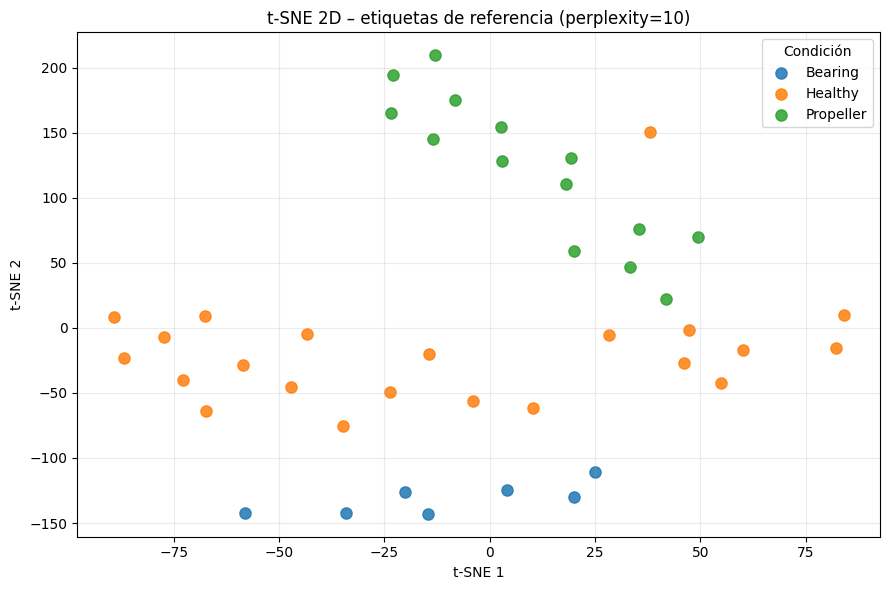

In [33]:
perplexity_tsne = min(10, max(2, (n_muestras - 1) // 3))
tsne = TSNE(
    n_components=2,
    perplexity=perplexity_tsne,
    init="pca",
    learning_rate=200,
    random_state=SEED
)
X_tsne = tsne.fit_transform(X_escalado)

df_tsne = metadatos_unsup.copy()
df_tsne["tSNE_1"] = X_tsne[:, 0]
df_tsne["tSNE_2"] = X_tsne[:, 1]
df_tsne.to_csv(RUTA_E3 / "coordenadas_tsne_2d.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(9, 6))
for clase in sorted(y_referencia.unique()):
    mascara = (y_referencia == clase).to_numpy()
    plt.scatter(X_tsne[mascara, 0], X_tsne[mascara, 1], label=clase, alpha=0.85, s=65)
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title(f"t-SNE 2D – etiquetas de referencia (perplexity={perplexity_tsne})")
plt.legend(title="Condición")
plt.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("05_tsne_etiquetas_referencia.png", "final")
plt.show()


## 28. Comparación de resultados y exportación

Las métricas **Silhouette** y **Davies–Bouldin** describen la cohesión/separación interna sin consultar etiquetas. **ARI** y **NMI** comparan, después del ajuste, los grupos encontrados con las condiciones reales. El número del clúster es arbitrario: por ejemplo, el clúster `0` no significa automáticamente `Healthy`.

Para DBSCAN, el ruido (`-1`) es una salida del algoritmo, no una cuarta clase mecánica. Si DBSCAN encuentra un solo grupo o marca casi todo como ruido, ese resultado debe presentarse como evidencia de que la configuración/representación no permitió encontrar varios grupos densos.



In [34]:
metricas_no_supervisadas = pd.DataFrame([
    {
        "Algoritmo": "K-means (PCA 2D)",
        "Numero_clusters": len(np.unique(clusters_kmeans)),
        "Puntos_ruido": 0,
        "Silhouette": silhouette_kmeans,
        "Davies_Bouldin": db_kmeans,
        "ARI_vs_etiqueta": ari_kmeans,
        "NMI_vs_etiqueta": nmi_kmeans
    },
    {
        "Algoritmo": "DBSCAN (PCA 2D)",
        "Numero_clusters": numero_clusters_dbscan,
        "Puntos_ruido": numero_ruido_dbscan,
        "Silhouette": silhouette_dbscan_final,
        "Davies_Bouldin": (
            davies_bouldin_score(X_pca[mascara_sin_ruido], clusters_dbscan[mascara_sin_ruido])
            if numero_clusters_dbscan >= 2 and mascara_sin_ruido.sum() > numero_clusters_dbscan
            else np.nan
        ),
        "ARI_vs_etiqueta": ari_dbscan,
        "NMI_vs_etiqueta": nmi_dbscan
    }
])

display(metricas_no_supervisadas)
metricas_no_supervisadas.to_csv(RUTA_E3 / "metricas_clustering.csv", index=False, encoding="utf-8-sig")
metricas_no_supervisadas.to_csv(RUTA_TABLAS_E3 / "metricas_clustering.csv", index=False, encoding="utf-8-sig")
df_busqueda_dbscan.to_csv(RUTA_TABLAS_E3 / "busqueda_parametros_dbscan.csv", index=False, encoding="utf-8-sig")

# Resumen combinado por grabación (referencia + métodos de clustering).
df_resultados_clustering = df_pca.copy()
df_resultados_clustering["cluster_kmeans"] = clusters_kmeans
df_resultados_clustering["cluster_dbscan"] = clusters_dbscan
df_resultados_clustering.to_csv(RUTA_E3 / "resumen_clustering_por_audio.csv", index=False, encoding="utf-8-sig")

# Guardar transformaciones y modelos para reproducir las proyecciones/clústeres.
joblib.dump({
    "imputador": imputador_unsup,
    "standard_scaler": escalador_unsup,
    "pca_2d": pca_2d,
    "kmeans": modelo_kmeans,
    "dbscan": modelo_dbscan,
    "columnas_caracteristicas": columnas_caracteristicas,
    "dbscan_eps": mejor_eps,
    "dbscan_min_samples": mejor_min_samples
}, RUTA_MODELOS_NO_SUP / "pipeline_clustering.joblib")

print("\nArchivos de la entrega final guardados en:", RUTA_E3)
print("Gráficas guardadas en:", RUTA_FIGURAS_E3)


,Algoritmo,Numero_clusters,Puntos_ruido,Silhouette,Davies_Bouldin,ARI_vs_etiqueta,NMI_vs_etiqueta
0,K-means (PCA 2D),3,0,0.623995,0.540284,0.231562,0.242657
1,DBSCAN (PCA 2D),2,7,0.763343,0.275944,0.223354,0.251677



Archivos de la entrega final guardados en: /content/data/entrega_final_no_supervisado
Gráficas guardadas en: /content/reports/figures/entrega_final


## Resultados organizados por entregas


**Entrega 01 – Exploración acústica**
- Se inspeccionaron las señales, se calcularon media, desviación estándar y RMS, y se conservaron IQR, espectrogramas y melspectrogramas.
- El inventario del dataset registra 43 audios: 22 `Healthy`, 14 `Propeller` y 7 `Bearing`.
- Cada audio se convirtió en un vector de 166 características acústicas a partir de Mel, MFCC y descriptores temporales/espectrales.

**Entrega 02 – Modelos supervisados**
- Se realizó una partición estratificada cercana a 80/20 y se compararon hiperparámetros mediante validación cruzada.
- Se evaluaron Decision Tree, Random Forest, SVM y redes MLP.
- En la ejecución previa registrada en el notebook, SVM obtuvo Accuracy y F1-macro de 1.00 sobre nueve audios de prueba; DT, RF y MLP obtuvieron 0.8889 de Accuracy y 0.8519 de F1-macro. Estas cifras deben recalcularse al ejecutar todo el notebook y no deben interpretarse como prueba de generalización debido al tamaño reducido de la muestra.

**Entrega final – Aprendizaje no supervisado**
- Se estandarizaron las características con `StandardScaler` para evitar que variables con magnitudes mayores dominen las distancias.
- PCA redujo las 166 características a dos componentes para visualización y clustering en el plano reducido. Se reporta la varianza explicada acumulada para conocer la información que conserva esa proyección.
- K-means se ajustó con tres clústeres, siguiendo el número de condiciones conocidas, sin utilizar las etiquetas durante el ajuste.
- DBSCAN buscó `eps` y `min_samples` mediante k-distancias y evaluación interna. El valor `-1` identifica ruido.
- t-SNE se incorpora como visualización complementaria, no como clasificador ni como reemplazo de PCA.

### Limitaciones que deben explicarse

- Solo hay 43 grabaciones; cualquier métrica varía mucho con pocos ejemplos.
- Las clases están desbalanceadas: `Bearing` cuenta con siete registros, frente a 22 `Healthy` y 14 `Propeller`.
- `Bearing` aparece asociado al motor M4 en el dataset suministrado. El modelo podría aprender rasgos del motor, además de rasgos de la condición.
- La validación supervisada se realiza por grabación, no por motor independiente. No se puede afirmar que el modelo generalice a motores nuevos ni a motocicletas reales.
- Las dos componentes PCA pueden no conservar toda la estructura de las 166 características. Los resultados K-means/DBSCAN de esta entrega corresponden al espacio PCA 2D definido en la guía.
- DBSCAN puede marcar puntos como ruido o no encontrar varios grupos. Eso es un resultado válido que debe explicarse, no ocultarse ni forzarse.
- Un valor atípico IQR o un punto ruido de DBSCAN no equivale automáticamente a una falla mecánica.


### Próximos pasos

Ampliar el dataset con más motores por condición, registrar cada condición en motores distintos y aumentar el número de grabaciones. Después se recomienda evaluar por motor independiente y validar en motores instalados en motocicletas reales.

### Referencia del dataset

Prieto Estacio, Bravo Montenegro & Rengifo Rodas (2023), *Dataset of audio signals from brushless DC motors for predictive maintenance*.


---

**Fin de la segunda presustentación.**

Antes de exponer, ejecutar todas las celdas en orden y actualizar las tablas y gráficas con los resultados reales del entorno. No se deben copiar métricas de una ejecución anterior: el notebook las calcula con la partición y los pesos generados en esa ejecución.